# Проект. Исследовательский анализ сервиса Яндекс Афиша
Автор: Хохлова Д.В.

Дата: 13.09.2026

## Введение
### Цели и задачи проекта 

**Цель:**
Исследовать изменения пользовательского спроса и популярности событий осенью 2024 года, а также сравнить поведение пользователей мобильных и стационарных устройств.

**Задачи:**

- Подготовить данные к анализу
- Изучить сезонные изменения в распределении заказов
- Проанализировать осеннюю активность пользователей
- Выделить топ регионов и партнёров по выручке
- Проверить статистические гипотезы
- Сформулировать выводы и рекомендации

### Описание данных

Первый датасет `final_tickets_orders_df.csv` включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. 

- order_id — уникальный идентификатор заказа.
- user_id — уникальный идентификатор пользователя.
- created_dt_msk — дата создания заказа (московское время).
- created_ts_msk — дата и время создания заказа (московское время).
- event_id — идентификатор мероприятия из таблицы events.
- cinema_circuit — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.
- age_limit — возрастное ограничение мероприятия.
- currency_code — валюта оплаты, например rub для российских рублей.
- device_type_canonical — тип устройства, с которого был оформлен заказ
- revenue — выручка от заказа.
- service_name — название билетного оператора.
- tickets_count — количество купленных билетов.
- total — общая сумма заказа.
- days_since_prev - количество дней с предыдущей покупки для каждого пользователя. Если покупки не было, то данные содержат пропуск.

Второй датасет `final_tickets_events_df` содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. Датасет содержит такие поля:

- event_id — уникальный идентификатор мероприятия.
- event_name — название мероприятия. 
- event_type_description — описание типа мероприятия.
- event_type_main — основной тип мероприятия: театральная постановка, концерт и так далее.
- organizers — организаторы мероприятия.
- region_name — название региона.
- city_name — название города.
- venue_id — уникальный идентификатор площадки.
- venue_name — название площадки.
- venue_address — адрес площадки.

Третий датасет `final_tickets_tenge_df.csv` содержит информацию о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. Датасет содержит такие поля:

- nominal — номинал (100 тенге).
- data — дата.
- curs — курс тенге к рублю.
- cdx — обозначение валюты (kzt).



### Содержимое проекта

1. Цели и задачи проекта
2. Загрузка данных и знакомство с ними
3. Предобработка данных и подготовка к исследованию
4. Исследовательский анализ данных
5. Статистический анализ данных
6. Итоговый вывод и рекомендации

##  Загрузка данных и знакомство с ними

In [1]:
# Импортируем необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats as st

Загрузим данные для каждого датасета, выведем первые строки и получим общую информацию: типы колонок, количество пропусков, размер данных 

In [2]:
orders = pd.read_csv('/datasets/final_tickets_orders_df.csv')
orders.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,Край билетов,4,10870.99,NaN
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,Мой билет,2,2067.51,NaN
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,За билетом!,4,13984.16,75.0
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,Лови билет!,2,212.28,NaN
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,Билеты без проблем,3,10695.43,83.0


In [3]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

In [4]:
events = pd.read_csv('/datasets/final_tickets_events_df.csv')
events.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [5]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


In [6]:
tenge = pd.read_csv('/datasets/final_tickets_tenge_df.csv')
tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [7]:
tenge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


Из трех датафреймов пропуски присутствуют только в колонке `days_since_prev` (268 909 непустых из 290 849) — это ожидаемо, так как для первых покупок значение отсутствует. Объём занимаемой памяти датафреймов небольшой, поэтому можно не снижать разрядность чиловых столбцов, так как экономия не даст существенного прироста в производительности. Типы данных и названия колонок в целом соответствуют логике колонок.

На этапе предобработки необходимо перевести `created_dt_msk` и `created_ts_msk` в формат datetime для корректной работы с датами и временем, проверить дубликаты, аномалии и выбросы, привести к единой валюте

## Предобработка данных и подготовка их к исследованию

### Изучим значения в ключевых столбцах для категориальных значений

In [8]:
# Посмотрим, какие значения есть в каждой категориальной колонке датафрейма orders
for col in ['age_limit', 'currency_code', 'device_type_canonical', 'service_name']:
    print(col, ':', orders[col].unique())

age_limit : [16  0 18 12  6]
currency_code : ['rub' 'kzt']
device_type_canonical : ['mobile' 'desktop']
service_name : ['Край билетов' 'Мой билет' 'За билетом!' 'Лови билет!'
 'Билеты без проблем' 'Облачко' 'Лучшие билеты' 'Прачечная' 'Быстробилет'
 'Дом культуры' 'Весь в билетах' 'Билеты в руки' 'Тебе билет!'
 'Show_ticket' 'Городской дом культуры' 'Яблоко' 'Билет по телефону'
 'Выступления.ру' 'Росбилет' 'Шоу начинается!' 'Мир касс' 'Восьмёрка'
 'Телебилет' 'Crazy ticket!' 'Реестр' 'Быстрый кассир' 'КарандашРУ'
 'Радио ticket' 'Дырокол' 'Вперёд!' 'Кино билет' 'Цвет и билет' 'Зе Бест!'
 'Тех билет' 'Лимоны' 'Билеты в интернете']


Все наименования в категориальных колонках датасета `orders` уникальны

In [9]:
# Проверим категориальные колонки датафрейма events
for col in ['event_type_description', 'event_type_main', 'region_name', 'city_name', 'venue_name']:
    print(f"-{col}: {events[col].unique()} ")

-event_type_description: ['спектакль' 'балет' 'мюзикл' 'опера' 'концерт' 'шоу' 'ёлка'
 'цирковое шоу' 'событие' 'фестиваль' 'спортивное мероприятие' 'выставка'
 'спорт' 'оперетта' 'экскурсия' 'рок-мюзикл' 'музыкальный спектакль'
 'снегурочка' 'подарок' 'кукольный спектакль'] 
-event_type_main: ['театр' 'концерты' 'ёлки' 'другое' 'стендап' 'выставки' 'спорт'] 
-region_name: ['Североярская область' 'Светополянский округ' 'Каменевский регион'
 'Лесодальний край' 'Медовская область' 'Широковская область'
 'Тепляковская область' 'Травяная область' 'Зоринский регион'
 'Серебринская область' 'Яблоневская область' 'Глиногорская область'
 'Речиновская область' 'Озернинский край' 'Горицветская область'
 'Солнечнореченская область' 'Травиницкий округ' 'Солнечноземская область'
 'Ключеводский округ' 'Островная область' 'Луговая область'
 'Каменноозёрный край' 'Лесостепной край' 'Зеленоградский округ'
 'Поленовский край' 'Лугоградская область' 'Синегорский регион'
 'Малиновая область' 'Речицкая обл

Так как в категориальных значениях датафрейма `events` много наименований и визуально сложно оценить их уникальность, проведем нормализацию данных на копии датафрейма. 

In [10]:
events_copy = events.copy()

In [11]:
# Приведем наименование нижнему регистру и удалим пробелы и внутренние кавычки
for col in ['region_name', 'city_name', 'venue_name']:
    events_copy[col] = events_copy[col].str.strip().str.lower().str.replace('"', '', regex=False)
    print(events[col].nunique(), events_copy[col].nunique())
    if events[col].nunique() == events_copy[col].nunique():
        print(f" {col} Количество не изменилось — дубликатов из-за регистра/пробелов не найдено")
    else:
        diff = events[col].nunique() - events_copy[col].nunique()
        print(f" {col} Найдено {diff} дубликатов, которые были скрыты за разным регистром/пробелами")

81 81
 region_name Количество не изменилось — дубликатов из-за регистра/пробелов не найдено
352 352
 city_name Количество не изменилось — дубликатов из-за регистра/пробелов не найдено
3217 3217
 venue_name Количество не изменилось — дубликатов из-за регистра/пробелов не найдено


После сравнения количества уникальных значений в датафрейме до нормализации и после, можно сделать вывод, что категориальные данные чистые без скрытых дубликатов.

### Изучим значения в ключевых столбцах для количественных значений

Для дальнейшего анализа объединим датафреймы `orders` и `events` в один общий `df`.

In [12]:
# Объединяем датафреймы
df= orders.merge(events, on = 'event_id', how = 'left')

# Проверим пропуски после объединения
print(f'Количество строк после объединения:{len(df)}')
print(f'Доля пропусков после объединения: ')
print(df.isna().sum()/len(df)*100)

Количество строк после объединения:290849
Доля пропусков после объединения: 
order_id                  0.000000
user_id                   0.000000
created_dt_msk            0.000000
created_ts_msk            0.000000
event_id                  0.000000
cinema_circuit            0.000000
age_limit                 0.000000
currency_code             0.000000
device_type_canonical     0.000000
revenue                   0.000000
service_name              0.000000
tickets_count             0.000000
total                     0.000000
days_since_prev           7.543433
event_name                0.081829
event_type_description    0.081829
event_type_main           0.081829
organizers                0.081829
region_name               0.081829
city_name                 0.081829
city_id                   0.081829
venue_id                  0.081829
venue_name                0.081829
venue_address             0.081829
dtype: float64


После объединения датафреймов в 238 строках (менее 0,1% от общего объёма данных) возникли пропуски. Это связано с особенностью выгрузки данных: при создании датасета `events` данные были отфильтрованы по категории «фильмы», тогда как в датафрейме `orders` такие заказы присутствовали. При объединении по идентификатору событий для этих заказов не нашлось соответствующих записей, что привело к пропускам в полях. Учитывая крайне малую долю таких записей (0,08%), пропуски не будут влиять на результаты анализа, поэтому принято решение их оставить без изменений.

Для анализа количественных столбцов проверим наличие выбросов в ключевых столбцах `revenue` и `tickets_count`.

In [13]:
# Посмотрим статистику по столбцу tickets_count
stats_tickets = (df['tickets_count']).describe()
stats_tickets

count    290849.000000
mean          2.754230
std           1.170467
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          57.000000
Name: tickets_count, dtype: float64

In [14]:
# Посмотрим статистику по кол-ву билетов в разрезе типа события
df.groupby('event_type_main')['tickets_count'].describe()

,count,mean,std,min,25%,50%,75%,max
event_type_main,,,,,,,,
выставки,4854.0,2.556654,1.072474,1.0,2.0,3.0,3.0,6.0
другое,65867.0,2.769642,1.255588,1.0,2.0,3.0,4.0,57.0
концерты,115276.0,2.656086,1.107536,1.0,2.0,3.0,3.0,12.0
спорт,21911.0,3.053215,1.271353,1.0,2.0,3.0,4.0,47.0
стендап,13393.0,2.992309,1.094416,1.0,2.0,3.0,4.0,6.0
театр,67321.0,2.759674,1.145821,1.0,2.0,3.0,4.0,19.0
ёлки,1989.0,3.344897,1.197205,1.0,2.0,3.0,4.0,8.0


Визуализируем выбросы с помощью диаграммы размаха

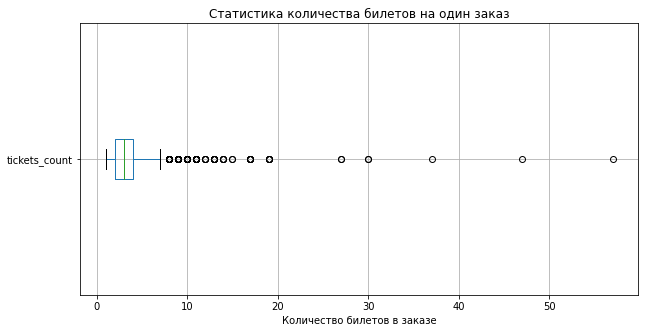

In [15]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df.boxplot(column='tickets_count', vert=False)

# Добавляем заголовок и метки оси
plt.title('Статистика количества билетов на один заказ')
plt.xlabel('Количество билетов в заказе')

# Выводим график
plt.show()

Анализ количества билетов в заказе показывает, что большинство пользователей приобретают от 2 до 4 билетов. Медианное значение составляет 3 билета, среднее — 2.75 билета. Стандартное отклонение (1.17) указывает на низкую вариативность показателя. Максимальное значение — 57 билетов относится к категории "другое", возможно какой-то корпоративный заказ.  Структура покупки билетов устойчива и практически не зависит от типа события — медиана везде равна 3, основная масса заказов — 2–4 билета. Различия между категориями проявляются в среднем значении и разбросе: семейные и групповые форматы («ёлки», «спорт») показывают чуть более высокие средние, а индивидуальные («выставки») — более низкие.

In [16]:
# Посмотрим статистику по столбцу revenue в валюте рубли
df_rub = df[df['currency_code']=='rub']
stats_rub = df_rub['revenue'].describe()
stats_rub

count    285780.000000
mean        547.568333
std         871.524559
min         -90.760000
25%         113.827500
50%         346.100000
75%         791.700000
max       81174.540000
Name: revenue, dtype: float64

Так как разброс значений слишком велик, для наглядности построим диаграмму размаха без учета выбросов

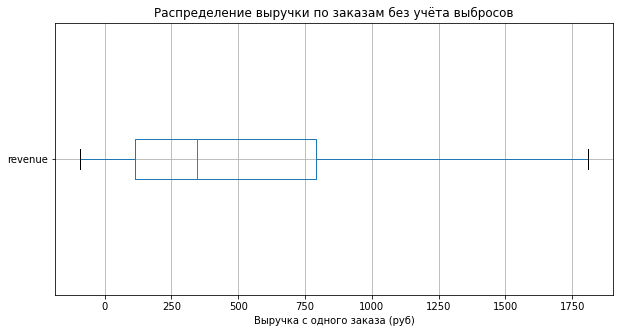

In [17]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df_rub.boxplot(column='revenue', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение выручки по заказам без учёта выбросов')
plt.xlabel('Выручка с одного заказа (руб)')

# Выводим график
plt.show()

In [18]:
# Рассчитаем квартили Q1 и Q3
Q1 = df_rub['revenue'].quantile(0.25)
Q3 = df_rub['revenue'].quantile(0.75)

# Рассчитаем межквартильный размах IQR как разницу между Q3 и Q1
IQR = Q3 - Q1

# Границы типичных значений (без выбросов)
# Рассчитаем нижний порог
lower_bound_df = Q1 - 1.5 * IQR

# Рассчитаем верхний порог
upper_bound_df = Q3 + 1.5 * IQR

# Выведем общую информацию
print(f"Q1 (25-й перцентиль): {Q1:.2f} руб")
print(f"Медиана: {df_rub['revenue'].quantile(0.5):.2f} руб")
print(f"Q3 (75-й перцентиль): {Q3:.2f} руб")
print(f"\nТипичный интервал (без выбросов):")
print(f"[{lower_bound_df:.2f} руб; {upper_bound_df:.2f} руб]")

Q1 (25-й перцентиль): 113.83 руб
Медиана: 346.10 руб
Q3 (75-й перцентиль): 791.70 руб

Типичный интервал (без выбросов):
[-902.98 руб; 1808.51 руб]


Распределение выручки в рублях сильно скошено вправо: медиана составляет 346 руб, а среднее — 548 руб. Это говорит о наличии дорогих заказов, которые «тянут» среднее вверх. Половина всех заказов приходится на диапазон 114–792 руб (Q1–Q3), а типичный интервал без выбросов — от −903 до 1809 руб. Стандартное отклонение (872 руб) превышает среднее, что подтверждает высокую вариативность. Максимальный заказ — 81175 руб — вероятно, корпоративная или групповая покупка. Также присутствуют заказы с отрицательной выручкой (минимум −90.76 руб) — это могут быть возвраты или технические корректировки.

In [19]:
# Посмотрим статистику по столбцу revenue в валюте тенге
df_kzt = df[df['currency_code']=='kzt']
stats_kzt = df_kzt['revenue'].describe()
stats_kzt

count     5069.000000
mean      4995.206767
std       4916.752776
min          0.000000
25%        518.100000
50%       3698.830000
75%       7397.660000
max      26425.860000
Name: revenue, dtype: float64

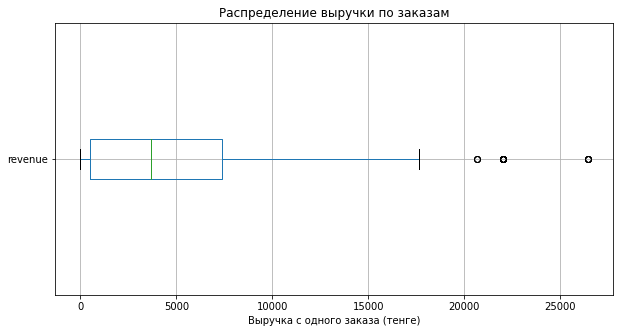

In [20]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df_kzt.boxplot(column='revenue', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение выручки по заказам')
plt.xlabel('Выручка с одного заказа (тенге)')

# Выводим график
plt.show()

In [21]:
# Рассчитаем квартили Q1 и Q3
Q1 = df_kzt['revenue'].quantile(0.25)
Q3 = df_kzt['revenue'].quantile(0.75)

# Рассчитаем межквартильный размах IQR как разницу между Q3 и Q1
IQR = Q3 - Q1

# Границы типичных значений (без выбросов)
# Рассчитаем нижний порог, как минимальное значение, т.к. финансирование не может быть отрицательным
lower_bound_df = Q1 - 1.5 * IQR

# Рассчитаем верхний порог
upper_bound_df = Q3 + 1.5 * IQR

# Выведем общую информацию
print(f"Q1 (25-й перцентиль): {Q1:.2f} руб")
print(f"Медиана: {df_kzt['revenue'].quantile(0.5):.2f} руб")
print(f"Q3 (75-й перцентиль): {Q3:.2f} руб")
print(f"\nТипичный интервал (без выбросов):")
print(f"[{lower_bound_df:.2f} тенге; {upper_bound_df:.2f} тенге]")

Q1 (25-й перцентиль): 518.10 руб
Медиана: 3698.83 руб
Q3 (75-й перцентиль): 7397.66 руб

Типичный интервал (без выбросов):
[-9801.24 тенге; 17717.00 тенге]


В тенге медиана 3699, среднее 4995. Распределение менее экстремальное, чем в рублях — нет таких сильных выбросов. Основная масса — 518–7398 тенге. Есть нулевые заказы (бесплатные/брони) и максимум 26426 тенге. 

Анализ распределения выручки выявил наличие значительных выбросов, а также заказов с отрицательными и нулевыми значениями. Для корректности дальнейшего анализа принято решение ограничить данные по верхней границе 99-м процентилем, что позволит исключить экстремально высокие значения, не характерные для основной массы заказов. При этом строки с отрицательной и нулевой выручкой сохранены, поскольку такие значения могут соответствовать возвратам билетов либо бесплатным мероприятиям с бронированием через сервис. 

In [22]:
# Отфильтруем датафремы по 99-му процентилю
df_kzt_99 = df_kzt[df_kzt['revenue']<=  df_kzt['revenue'].quantile(0.99)]
df_rub_99 = df_rub[df_rub['revenue']<= df_rub['revenue'].quantile(0.99)]

In [23]:
# Объединим обратно датафреймы после фильтрации по 99 процентилю
df_1 = pd.concat([df_rub_99, df_kzt_99], ignore_index=True)

Проведем анализ по кол-ву заказов на одного пользователя

In [24]:
user_orders = df.user_id.value_counts()
print(user_orders.describe())

count    21940.000000
mean        13.256563
std        122.534821
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10258.000000
Name: user_id, dtype: float64


Выведем id пользователей с максимальными количествами заказов

In [25]:
df['user_id'].value_counts().head(10)

0beb8fc0c0a9ce1    10258
18e9aead0a393e7     4368
8187dac4be757a0     4061
3ee7dc2e115847f     3833
7eb4fc207ecc10f     3751
1c2a2133e1df1b4     3539
4ec8f6429431987     3413
ad2dc32364ed948     3279
b54dd0cd81121fc     3164
cdbc02c6ad8087a     3072
Name: user_id, dtype: int64

Проанализируем среднее количество билетов и выручку пользователя с максимальным количеством заказов

In [26]:
df[df.user_id =='0beb8fc0c0a9ce1']['tickets_count'].mean() 

2.8736595827646716

In [27]:
df_kzt[df_kzt.user_id =='0beb8fc0c0a9ce1']['revenue'].mean()

6233.163478260871

In [28]:
df_rub[df_rub.user_id =='0beb8fc0c0a9ce1']['revenue'].mean()

518.3313563647071

В ходе анализа был выявлен пользователь с аномально высоким числом заказов (10258 заказов). Однако при детальном рассмотрении было установлено, что его поведение не отклоняется от нормы: среднее количество билетов на один его заказ составляет 2.87, что практически совпадает с медианным значением по всему датафрейму (3 билета). Средняя выручка в обеих валютах так же находится в пределах 75 процентиля.

Таким образом, данный пользователь не является скупщиком билетов и не искажает структуру спроса (покупает как обычный пользователь, просто чаще), а представляет собой крупного корпоративного клиента, совершающего большое число типовых покупок. Удаление не изменит средний чек и среднее число билетов, но удалить его  — это потерять значимый кусок данных для топ-событий и динамики. В связи с этим принято решение не исключать его из анализа.

### Проверка на дубликаты

Проверим дубликаты по всем столбцам, кроме order_id, который является первичным ключом таблицы purchases

In [29]:
# Все колонки, кроме order_id
cols_to_check = [col for col in df_1.columns if col != 'order_id']

# Проверяем дубликаты
duplicates = df_1[df_1.duplicated(subset=cols_to_check, keep=False)]
print(f"Найдено дубликатов: {len(duplicates)}")

Найдено дубликатов: 58


In [30]:
# Посмотрим на эти дубликаты
duplicates

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
11496,1123983,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
11497,1123867,06eb7897f65b433,2024-08-13,2024-08-13 16:31:07,183706,нет,18,rub,mobile,69.82,...,69796237-909b-42a7-bfb5-c1b8574c4c76,спектакль,театр,№1482,Светополянский округ,Глиноград,54.0,4443.0,"Центр культурного наследия ""Объединение"" и пар...","бул. Карбышева, д. 50"
55833,160922,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,...,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,выставка,другое,№1810,Яблоневская область,Горяново,11036.0,1656.0,"Модная академия ""Пункт"" Лимитед","бул. Гагарина, д. 39"
55836,160893,2564e3703075008,2024-10-30,2024-10-30 10:04:15,589005,нет,6,rub,mobile,11.23,...,bee8d0cc-282b-492e-9ed8-ec0990f43ffd,выставка,другое,№1810,Яблоневская область,Горяново,11036.0,1656.0,"Модная академия ""Пункт"" Лимитед","бул. Гагарина, д. 39"
81773,3363711,3ee7dc2e115847f,2024-06-25,2024-06-25 07:32:08,277504,нет,6,rub,mobile,59.19,...,dcb6fe75-8502-480d-b8a2-6bee187cb7ee,событие,выставки,№5015,Нежинская область,Каменёвка,76.0,3094.0,"Сообщество художников ""Палитра"" и партнеры","пр. Театральный, д. 161 стр. 2"
81778,3363798,3ee7dc2e115847f,2024-06-25,2024-06-25 07:32:08,277504,нет,6,rub,mobile,59.19,...,dcb6fe75-8502-480d-b8a2-6bee187cb7ee,событие,выставки,№5015,Нежинская область,Каменёвка,76.0,3094.0,"Сообщество художников ""Палитра"" и партнеры","пр. Театральный, д. 161 стр. 2"
144476,2324032,7b525118ae656af,2024-10-28,2024-10-28 08:33:04,588203,нет,0,rub,mobile,26.96,...,88478781-0311-42e3-b0ea-d4d6a171b70a,спорт,спорт,№1503,Чистогорская область,Песчанская,21.0,2155.0,"Клуб моделей ""Гармония"" Инк","ул. Прохладная, д. 8 к. 432"
144480,2323916,7b525118ae656af,2024-10-28,2024-10-28 08:33:04,588203,нет,0,rub,mobile,26.96,...,88478781-0311-42e3-b0ea-d4d6a171b70a,спорт,спорт,№1503,Чистогорская область,Песчанская,21.0,2155.0,"Клуб моделей ""Гармония"" Инк","ул. Прохладная, д. 8 к. 432"
150002,5372628,7eb4fc207ecc10f,2024-08-23,2024-08-23 14:08:19,298035,нет,6,rub,mobile,126.84,...,09164a56-0fb3-43c7-91d3-8ed22bb3d8ef,событие,другое,№4403,Североярская область,Озёрск,2.0,2795.0,"Клуб исторических реконструкций ""Логос"" и парт...","пр. Пушкина, д. 8/6 к. 482"
150005,5372831,7eb4fc207ecc10f,2024-08-23,2024-08-23 14:08:19,298035,нет,6,rub,mobile,126.84,...,09164a56-0fb3-43c7-91d3-8ed22bb3d8ef,событие,другое,№4403,Североярская область,Озёрск,2.0,2795.0,"Клуб исторических реконструкций ""Логос"" и парт...","пр. Пушкина, д. 8/6 к. 482"


В ходе анализа были выявлены полные дубликаты записей, которые было принято решение удалить. Их появление, вероятнее всего, связано с техническими сбоями: ошибкой при оплате или зависанием сайта в момент оформления заказа. В результате одна и та же покупка могла быть зафиксирована в системе несколько раз под разными номерами заказов.

In [31]:
# Удалим дубликаты, оставив первое вхождение 
df_2 = df_1.drop_duplicates(subset=cols_to_check, keep='first').reset_index(drop=True)

### Преобразование типов данных и создание новых столбцов
Обработаем типы данных в столбцах, которые хранят значения даты

In [32]:
# Список колонок для преобазования в datetime
col = ['created_dt_msk', 'created_ts_msk']

# Преобразуем тип данных
df_2[col] = df_2[col].apply(pd.to_datetime, errors='coerce')
tenge['data']=tenge['data'].apply(pd.to_datetime, errors='coerce')

Создадим дополнительные столбцы, которые нужны будут для дальнейшего анализа

In [33]:
# Переименовываем колонку c датой в датасете tenge, чтобы она совпадала с df_2
tenge_renamed = tenge.rename(columns={'data': 'created_dt_msk'})

# Соединим датафреймы  по общей колонке
df_3 = pd.merge(df_2, tenge_renamed, on='created_dt_msk', how='left')

In [34]:
# Приведем выручку к одной валюте - рубли
df_3['revenue_rub'] = np.where(
    df_3['currency_code'] == 'rub',
    df_3['revenue'],
    df_3['revenue'] / df_3['nominal'] * df_3['curs']
).round(2)

In [35]:
# Рассчитаем выручку с продажи одного билета
df_3['one_ticket_revenue_rub'] = df_3['revenue_rub']/ df_3['tickets_count']

In [36]:
# Выделим месяц оформления заказа
df_3['month'] = df_3['created_dt_msk'].dt.month

In [37]:
# Создадим столбец с информацией о сезонности
df_3['month'] = df_3['month'].astype(int)

df_3['season'] = pd.cut(
    df_3['month'], 
    bins=[1,3,6,9,12,13], 
    labels=['зима', 'весна', 'лето', 'осень' , 'зима'], 
    right = False,
    ordered=False
)

Выведем новые столбцы, чтобы проверить, что столбцы действительно созданы,  и  значения корректны.

In [124]:
df_3[['created_dt_msk', 'currency_code', 'revenue', 'nominal', 'curs', 'revenue_rub', 'one_ticket_revenue_rub', 'month', 'season']].head()

,created_dt_msk,currency_code,revenue,nominal,curs,revenue_rub,one_ticket_revenue_rub,month,season
0,2024-08-20,rub,1521.94,100,18.6972,1521.94,380.4850,8,лето
1,2024-07-23,rub,289.45,100,18.3419,289.45,144.7250,7,лето
2,2024-10-06,rub,1258.57,100,19.6475,1258.57,314.6425,10,осень
3,2024-07-13,rub,8.49,100,18.5010,8.49,4.2450,7,лето
4,2024-10-04,rub,1390.41,100,19.6648,1390.41,463.4700,10,осень


In [38]:
# Выводим результаты после предобработки по количественным значениям

print(f"Количество строк до предобработки данных: {len(df)}")
print(f"Количество строк после предобработки данных: {len(df_3)}")
print(f"Количество удаленных строк после предобработки в абсолютном значении: " \
      f"{len(df) - len(df_3)}")
print(f"Процент потерь: " \
      f"{round((len(df) - len(df_3))/len(df),4)*100} %")

Количество строк до предобработки данных: 290849
Количество строк после предобработки данных: 287932
Количество удаленных строк после предобработки в абсолютном значении: 2917
Процент потерь: 1.0 %


**Вывод после предобработки**
1. Общая информация о данных
- Размер исходного (объединенного) датасета -  290849 строк и 23 столбца
- Размер после всех преобразований - 287932 строки и 31 столбец
- Данные содержат информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных, о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия, данные о курсе тенге к российскому рублю за 2024 год.

2. Типы данных
- Были выполнены преобразования колонок с датой к типу datetime. 
- Объём занимаемой памяти датафрейма небольшой, поэтому было принято не снижать разрядность чиловых столбцов, так как экономия не даст существенного прироста в производительности.
- Так же были обработаны аномалии в столбце `revenue` и отфильтрованы по 99 процентилю. 

3. Пропуски

После объединения датафреймов в 238 строках возникли пропуски. Это связано с особенностью выгрузки данных (фильтрация по категории «фильмы» в датасете final_tickets_events_df). Учитывая крайне малую долю таких записей (0,08%), пропуски не будут влиять на результаты анализа, поэтому принято решение их оставить без изменений.

4. Дубликаты
- Количество явных дубликатов (полных) - 0
- Количество неявных дубликатов (по бронированию билета без учёта идентификаторов заказа) - 58
- Удалили 58 неявных дубликата

5. Были созданы дополнительные столбцы:

- revenue_rub — выручка в рублях. 
- one_ticket_revenue_rub — выручка с продажи одного билета на мероприятие.
- month —  месяц оформления.
- season —  столбец с информацией о сезонности ('лето', 'осень', 'зима', 'весна').


6. Итоговое состояние данных

Количество строк после всех преобразований  287932

Количество удаленных строк после предобработки в абсолютном значении: 2917

На этом предобработка завершена. Данные готовы для дальнейшего исследования

## Исследовательский анализ данных

### Анализ распределения заказов по сегментам и их сезонные изменения


   На стадии исследовательского анализа изучим изменение пользовательской активности или пользовательского интереса в связи с сезонностью. Анализируем динамику по следующим разрезам:
- тип мероприятия `event_type_main`;
- тип устройства `device_type_canonical`;
- категория мероприятий по возрастному рейтингу `age_limit`

Изучим распределение заказов по сегментам и их сезонные изменения, выполнив следующие шаги:

1. Для каждого месяца найдем количество заказов и визуализируем результаты. Проверим, фиксируется ли увеличение заказов от июня к ноябрю 2024 года.

In [39]:
# Посчитаем количество заказов для каждого месяца
orders_per_month = df_3.groupby('month')['order_id'].count()
dict = {6:'Июнь', 7:'Июль', 8:'Август', 9:'Сентябрь', 10:'Октябрь'}
print(orders_per_month.rename(index=dict))

month
Июнь        34343
Июль        40410
Август      44572
Сентябрь    69333
Октябрь     99274
Name: order_id, dtype: int64


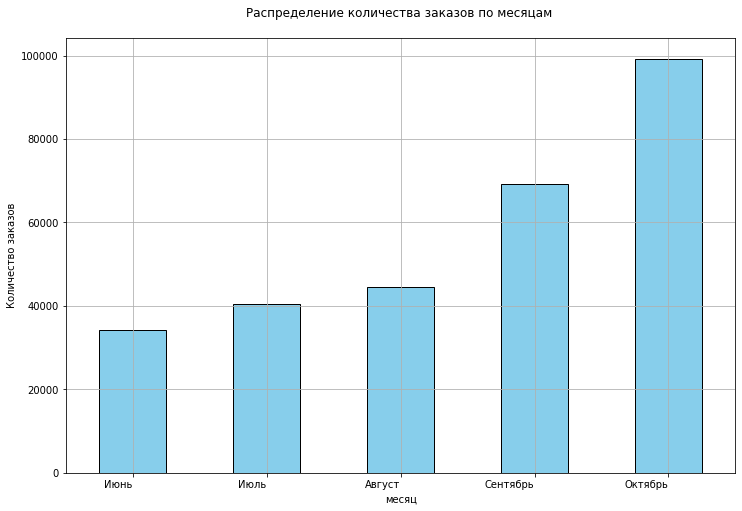

In [40]:
# Визуализируем результаты
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(12, 8))

# Строим столбчатую диаграмму 
orders_per_month.rename(index=dict).plot(
               kind='bar',
               title=f'Распределение количества заказов по месяцам \n',
               color='skyblue',
               edgecolor='black'
)


plt.xlabel('месяц')
plt.ylabel('Количество заказов')
plt.xticks(rotation=0, ha='right')
plt.grid()

plt.show()

Вывод: на графике видим рост количества заказов от июня к октябрю почти в 3 раза

2. Для осеннего и летнего периодов сравним распределение заказов билетов по разным категориям: тип мероприятия, тип устройства, категория мероприятия по возрастному рейтингу. 

In [41]:
# Выделим отдельно летний и осенний датасет
df_sum = df_3[df_3.season == 'лето']
df_aut= df_3[df_3.season == 'осень']

In [42]:
# Рассчитаем доли заказов по типам мероприятий в летний и осенний период
order_event = pd.concat([df_sum.event_type_main.value_counts(normalize=True).rename('Лето'), 
           df_aut.event_type_main.value_counts(normalize=True).rename('Осень')], 
          axis=1)
order_event

,Лето,Осень
концерты,0.426139,0.371884
другое,0.271759,0.197082
театр,0.201009,0.253492
стендап,0.053279,0.041065
спорт,0.025237,0.111997
выставки,0.020284,0.014450
ёлки,0.002292,0.010031


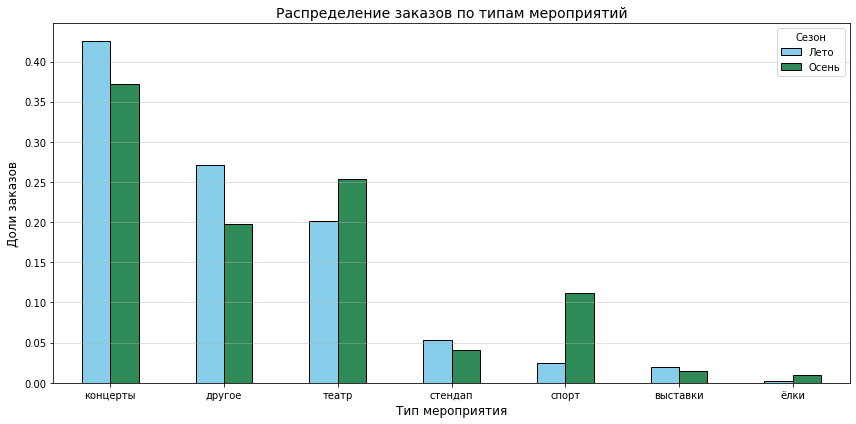

In [43]:
# Строим столбчатую диаграмму
order_event.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'], 
    edgecolor='black'
)

plt.title('Распределение заказов по типам мероприятий', fontsize=14)
plt.xlabel('Тип мероприятия', fontsize=12)
plt.ylabel('Доли заказов', fontsize=12)
plt.xticks(rotation=0, ha='center')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [44]:
# Рассчитаем среднемесячное количество заказов по типам мероприятий
order_event_abs = pd.concat([df_sum.event_type_main.value_counts().rename('Лето'), 
           df_aut.event_type_main.value_counts().rename('Осень')], 
          axis=1)
order_event_abs['Лето'] = round(order_event_abs['Лето']/3 , 0)
order_event_abs['Осень'] = round(order_event_abs['Осень']/2, 0 )
order_event_abs

,Лето,Осень
концерты,16919.0,31347.0
другое,10790.0,16612.0
театр,7981.0,21368.0
стендап,2115.0,3462.0
спорт,1002.0,9440.0
выставки,805.0,1218.0
ёлки,91.0,846.0


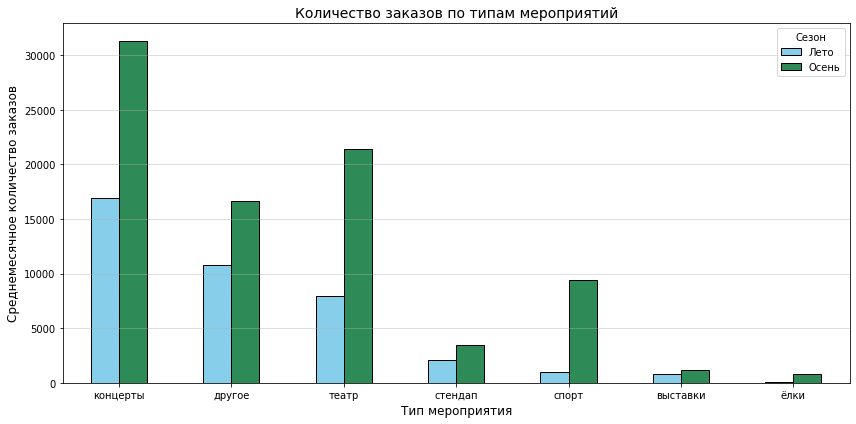

In [45]:
# Строим столбчатую диаграмму
order_event_abs.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'], 
    edgecolor='black'
)

plt.title('Количество заказов по типам мероприятий', fontsize=14)
plt.xlabel('Тип мероприятия', fontsize=12)
plt.ylabel('Среднемесячное количество заказов', fontsize=12)
plt.xticks(rotation=0, ha='center')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

Вывод: Осенний сезон характеризуется ростом числа заказов по всем категориям, но структура спроса сдвигается — доля концертов и «другого» снижается, а театра и спорта растёт. Это может быть связано с началом театрального сезона и спортивных чемпионатов осенью, а также с возвращением аудитории после летних отпусков.

In [46]:
# Рассчитаем долю заказов по типу устройства в летний и осенний период
order_device = pd.concat([df_sum.device_type_canonical.value_counts(normalize=True).rename('Лето'), 
           df_aut.device_type_canonical.value_counts(normalize=True).rename('Осень')], 
          axis=1)
order_device

,Лето,Осень
mobile,0.806386,0.796551
desktop,0.193614,0.203449


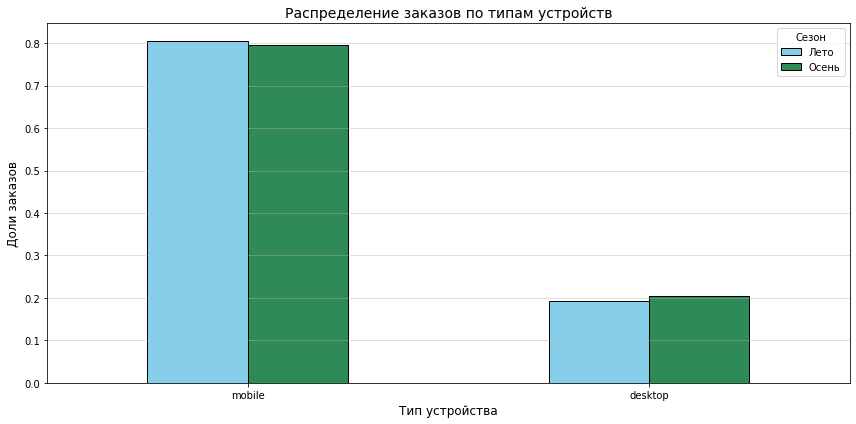

In [47]:
# Строим столбчатую диаграмму
order_device.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'],
    edgecolor='black'
)

plt.title('Распределение заказов по типам устройств', fontsize=14)
plt.xlabel('Тип устройства', fontsize=12)
plt.ylabel('Доли заказов', fontsize=12)
plt.xticks(rotation=0, ha='center')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [48]:
# Рассчитаем среднемесячное количество заказов по типу устройства
order_device_abs = pd.concat([df_sum.device_type_canonical.value_counts().rename('Лето'), 
           df_aut.device_type_canonical.value_counts().rename('Осень')], 
          axis=1)
order_device_abs['Лето'] = round(order_device_abs['Лето']/3 , 0)
order_device_abs['Осень'] = round(order_device_abs['Осень']/2, 0 )
order_device_abs 

,Лето,Осень
mobile,32074.0,67152.0
desktop,7701.0,17152.0


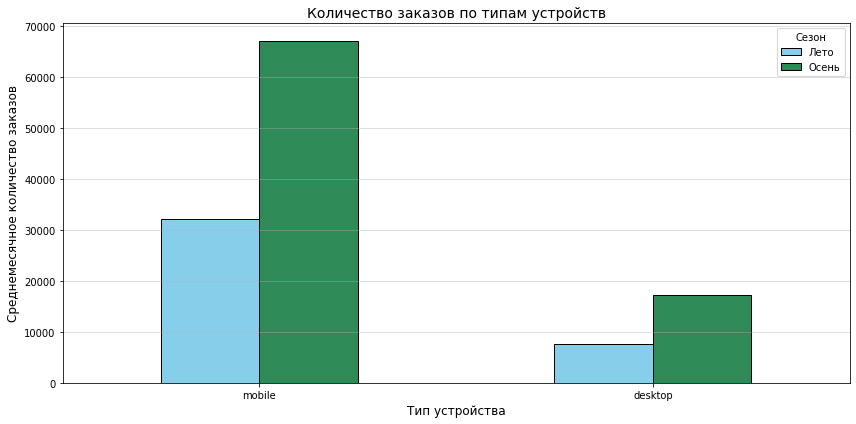

In [49]:
# Строим столбчатую диаграмму
order_device_abs.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'],
    edgecolor='black'
)

plt.title('Количество заказов по типам устройств', fontsize=14)
plt.xlabel('Тип устройства', fontsize=12)
plt.ylabel('Среднемесячное количество заказов', fontsize=12)
plt.xticks(rotation=0, ha='center')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

Вывод: Структура заказов по устройствам стабильна — мобильные дают ~80%, десктоп — ~20%, и это не меняется от летнего к осеннему сезону. Рост осенью идёт пропорционально по обоим каналам. Таким образом мобильные — основной канал независимо от сезона.

In [50]:
# Рассчитаем долю заказов по возрастному рейтингу в летний и осенний период
order_age = pd.concat([df_sum.age_limit.value_counts(normalize=True).rename('Лето'), 
           df_aut.age_limit.value_counts(normalize=True).rename('Осень')], 
          axis=1)
order_age

,Лето,Осень
0,0.179376,0.236218
6,0.181680,0.176298
12,0.205489,0.220827
16,0.283076,0.262255
18,0.150379,0.104403


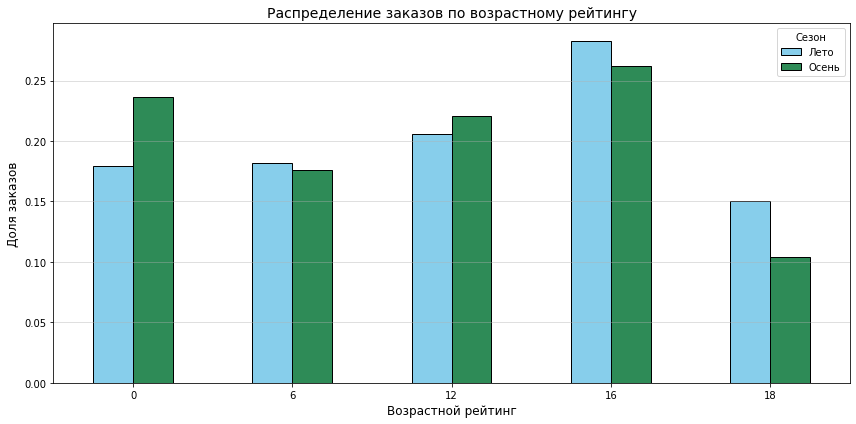

In [51]:
# Строим столбчатую диаграмму
order_age.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'],
    edgecolor='black'
)

plt.title('Распределение заказов по возрастному рейтингу', fontsize=14)
plt.xlabel('Возрастной рейтинг', fontsize=12)
plt.ylabel('Доля заказов', fontsize=12)
plt.xticks(rotation=0, ha='center')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

In [52]:
# Рассчитаем среднемесячное количество заказов по возрастному рейтингу
order_age_abs = pd.concat([df_sum.age_limit.value_counts().rename('Лето'), 
           df_aut.age_limit.value_counts().rename('Осень')], 
          axis=1)
order_age_abs['Лето'] = round(order_age_abs['Лето']/3 , 0)
order_age_abs['Осень'] = round(order_age_abs['Осень']/2, 0 )
order_age_abs

,Лето,Осень
0,7135.0,19914.0
6,7226.0,14862.0
12,8173.0,18616.0
16,11259.0,22109.0
18,5981.0,8802.0


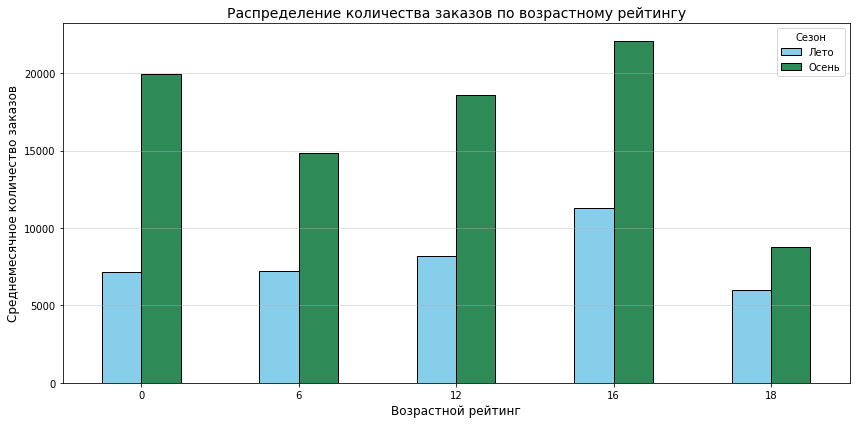

In [53]:
# Строим столбчатую диаграмму
order_age_abs.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'],
    edgecolor='black'
)

plt.title('Распределение количества заказов по возрастному рейтингу', fontsize=14)
plt.xlabel('Возрастной рейтинг', fontsize=12)
plt.ylabel('Среднемесячное количество заказов', fontsize=12)
plt.xticks(rotation=0, ha='center')
plt.legend(title='Сезон')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

Вывод: Возрастной профиль аудитории сдвигается — растёт доля 0+ (с 17.9% до 23.6%) и 12+, снижается 16+ и особенно 18+ (с 15.0% до 10.4%). В абсолютных значениях заказы выросли по всем категориям, но структура изменилась: осенью больше «семейных» категорий. 

3. Изучим изменение выручки с продажи одного билета в зависимости от типа мероприятия летом и осенью.

In [54]:
revenue_event = pd.concat([df_sum.groupby('event_type_main')['one_ticket_revenue_rub'].mean().rename('Лето'), 
           df_aut.groupby('event_type_main')['one_ticket_revenue_rub'].mean().rename('Осень')], 
          axis=1)
revenue_event

,Лето,Осень
event_type_main,,
выставки,86.416198,90.603610
другое,77.433970,76.115335
концерты,304.717082,268.084074
спорт,50.761839,49.969733
стендап,218.518107,231.124973
театр,214.126333,175.969508
ёлки,271.436176,229.585589


In [55]:
revenue_event['Изменение (%)'] = (revenue_event['Осень'] - revenue_event['Лето'])/revenue_event['Лето']*100
revenue_event

,Лето,Осень,Изменение (%)
event_type_main,,,
выставки,86.416198,90.603610,4.845634
другое,77.433970,76.115335,-1.702914
концерты,304.717082,268.084074,-12.021974
спорт,50.761839,49.969733,-1.560436
стендап,218.518107,231.124973,5.769254
театр,214.126333,175.969508,-17.819772
ёлки,271.436176,229.585589,-15.418205


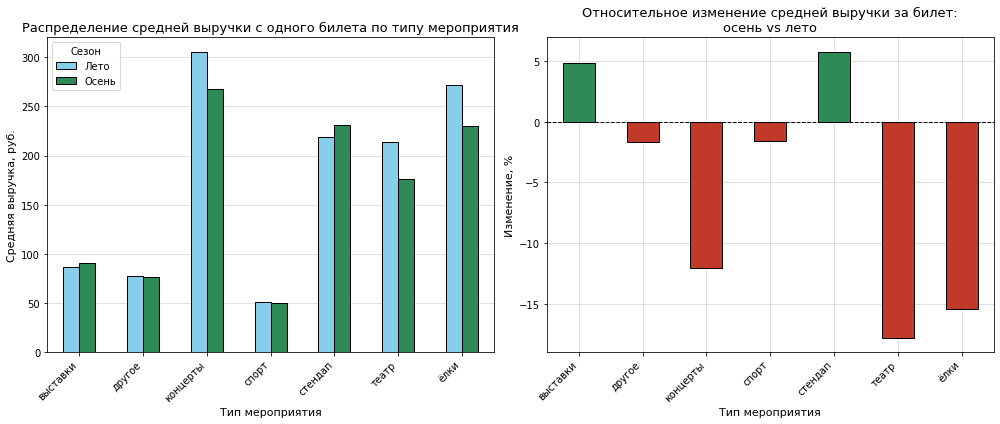

In [56]:
# Создаём фигуру и две оси (1 строка, 2 столбца)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# график 1
revenue_event[['Лето', 'Осень']].plot(
    kind='bar',
    ax=ax1,
    color=['skyblue', 'seagreen'],
    edgecolor='black')

# Подписи и заголовок
ax1.set_title('Распределение средней выручки с одного билета по типу мероприятия', fontsize=13)
ax1.set_xlabel('Тип мероприятия', fontsize=11)
ax1.set_ylabel('Средняя выручка, руб.', fontsize=11)
ax1.tick_params(axis='x', rotation=45)
plt.setp(ax1.get_xticklabels(), ha='right')
ax1.legend(title='Сезон')
ax1.grid(axis='y', alpha=0.5)
ax1.set_axisbelow(True)


# график 2
colors = ['#2E8B57' if v >= 0 else '#C0392B' for v in revenue_event['Изменение (%)']]
revenue_event['Изменение (%)'].plot(
    kind='bar',
    ax=ax2,
    color=colors,
    edgecolor='black'
)

ax2.axhline(y=0, color='black', linewidth=1, linestyle='--')

ax2.set_title('Относительное изменение средней выручки за билет:\nосень vs лето', fontsize=13)
ax2.set_xlabel('Тип мероприятия', fontsize=11)
ax2.set_ylabel('Изменение, %', fontsize=11)
ax2.tick_params(axis='x', rotation=45)
plt.setp(ax2.get_xticklabels(), ha='right')

ax2.grid(alpha=0.5)
ax2.set_axisbelow(True)


plt.tight_layout()
plt.show()

Вывод: единого тренда в изменении выручки с продажи одного билета нет — динамика разнонаправленная.  В большинстве категорий средняя стоимость билета снизилась: сильнее всего в театре (−17.8%), ёлках (−15.4%) и концертах (−12.0%). При этом стендап (+5.8%) и выставки (+4.8%) подорожали, а изменения по «другому» и спорту минимальны (−1.7% и −1.6%).

Самые дорогие билеты — на концерты (305 руб летом, 268 руб осенью) и ёлки (271 руб летом). Самые дешёвые — на спорт (50 руб) и «другое» (77 руб). 

Это говорит о том, что изменение стоимости билета связано не с общим сезонным фактором, а с ассортиментом мероприятий внутри каждой категории.

###  Осенняя активность пользователей

Изучим активность пользователей осенью 2024 года. Проанализируем динамику изменений по дням для:

- общего числа заказов;
- количества активных пользователей DAU;
- среднего числа заказов на одного пользователя;
- средней стоимости одного билета.

In [57]:
# Создадим сводную таблицу
pivot = df_aut.pivot_table(
    index='created_dt_msk',
    values=['order_id', 'user_id',  'one_ticket_revenue_rub'],
    aggfunc={'order_id': 'count', 'user_id': 'nunique','one_ticket_revenue_rub': 'mean'} 
)
pivot

,one_ticket_revenue_rub,order_id,user_id
created_dt_msk,,,
2024-09-01,200.168718,1327,564
2024-09-02,189.464638,1380,574
2024-09-03,80.130105,5111,778
2024-09-04,177.685593,1773,685
2024-09-05,189.510149,1944,739
...,...,...,...
2024-10-27,186.968327,2849,1034
2024-10-28,170.654941,2838,985
2024-10-29,177.409613,2836,998


In [58]:
# Посчитаем среднее число заказов на одного пользователя;
pivot['order_per_user']= pivot['order_id']/pivot['user_id']

In [59]:
# Переименуем колонки
pivot = pivot.rename(columns={
    'order_id': 'orders',
    'user_id': 'dau',
    'one_ticket_revenue_rub':'avg_ticket_rev'
})
print(pivot.to_string())

                avg_ticket_rev  orders   dau  order_per_user
created_dt_msk                                              
2024-09-01          200.168718    1327   564        2.352837
2024-09-02          189.464638    1380   574        2.404181
2024-09-03           80.130105    5111   778        6.569409
2024-09-04          177.685593    1773   685        2.588321
2024-09-05          189.510149    1944   739        2.630582
2024-09-06          174.787318    2125   864        2.459491
2024-09-07          190.144168    1959   794        2.467254
2024-09-08          181.973169    1713   717        2.389121
2024-09-09          159.346513    2094   779        2.688062
2024-09-10          183.145534    2020   762        2.650919
2024-09-11          177.107552    2222   816        2.723039
2024-09-12          184.058941    2322   859        2.703143
2024-09-13          174.607484    2720   946        2.875264
2024-09-14          177.377010    2330   839        2.777116
2024-09-15          189.

Так как разброс значений в столбцах от нескольких единиц до нескольких тысяч, то визуализировать динамику удобнее на каждом отдельном графике.

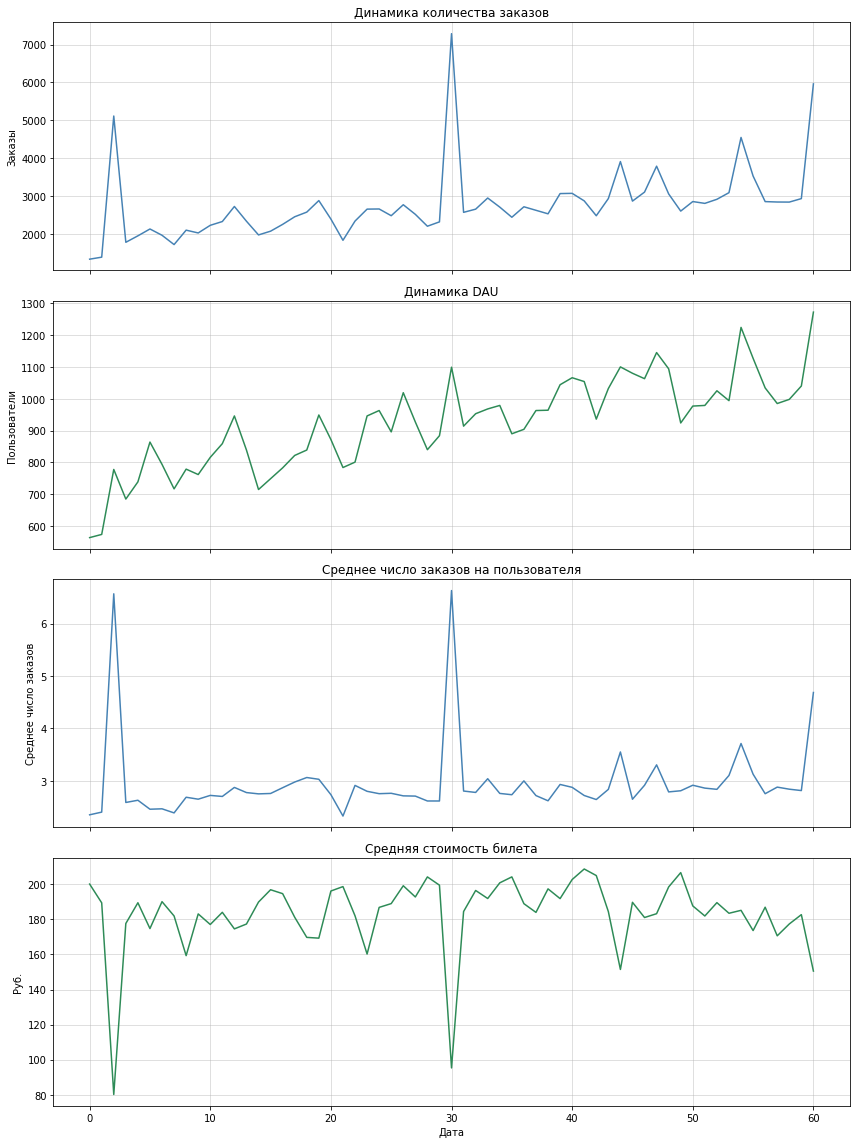

In [127]:
fig, axes = plt.subplots(4, 1, figsize=(12, 16), sharex=True)

pivot['orders'].plot.line(ax=axes[0], color='steelblue')
axes[0].set_title('Динамика количества заказов')
axes[0].set_ylabel('Заказы')

pivot['dau'].plot.line(ax=axes[1], color='seagreen')
axes[1].set_title('Динамика DAU')
axes[1].set_ylabel('Пользователи')

pivot['order_per_user'].plot.line(ax=axes[2], color='steelblue')
axes[2].set_title('Среднее число заказов на пользователя')
axes[2].set_ylabel('Среднее число заказов')

pivot['avg_ticket_rev'].plot.line(ax=axes[3], color='seagreen')
axes[3].set_title('Средняя стоимость билета')
axes[3].set_ylabel('Руб.')

for ax in axes:
    ax.grid(alpha=0.5)
    ax.set_axisbelow(True)

axes[3].set_xlabel('Дата')
plt.tight_layout()
plt.show()

Вывод:

1. Общее число заказов

Количество заказов варьируется от ~1300 до ~7 00 в день.

Средний уровень — около 2500–3000 заказов в день.

Есть три основных пика 5111 (вторник 3 сентября), 7288 (вторник 1 октября), 5961 (четверг 31 октября). Эти всплески в 2–3 раза выше обычного.

2. Количество активных пользователей (DAU)

DAU стабильно растёт от начала периода к концу: с ~560–780 в начале до ~1000–1270 в конце.
Это говорит о росте популярности сервиса.


Средний уровень — около 900 пользователей.

3. Среднее число заказов на пользователя

Большинство дней — 2–3 заказа на пользователя.

Аномальные пики (~ 6 билетов)— в те же дни, что и пики по количеству заказов. Вероятно, корпоративные или групповые покупки.

К концу периода активность растёт.

4. Средняя стоимость одного билета

Большинство дней — ~ 170–190 руб за билет.

Дни с аномальными провалами совпадают с днями анопальных пиков по количеству заказов. В эти дни много заказов, но дешёвые билеты.


Изучим недельную цикличность.  Сравним пользовательскую активность в будни и выходные.

In [61]:
pivot = pivot.reset_index().rename(columns={'created_dt_msk': 'date'})

In [62]:
# Выделим день недели
pivot['date'] = pivot['date'].dt.day_name()

In [63]:
# Определим будний или выходной день
pivot['type_of_day'] = np.where(pivot['date'].isin(['Saturday', 'Sunday']), 'Выходной', 'Будни')
pivot

,date,avg_ticket_rev,orders,dau,order_per_user,type_of_day
0,Sunday,200.168718,1327,564,2.352837,Выходной
1,Monday,189.464638,1380,574,2.404181,Будни
2,Tuesday,80.130105,5111,778,6.569409,Будни
3,Wednesday,177.685593,1773,685,2.588321,Будни
4,Thursday,189.510149,1944,739,2.630582,Будни
...,...,...,...,...,...,...
56,Sunday,186.968327,2849,1034,2.755319,Выходной
57,Monday,170.654941,2838,985,2.881218,Будни
58,Tuesday,177.409613,2836,998,2.841683,Будни
59,Wednesday,182.729053,2928,1040,2.815385,Будни


In [128]:
# Сгруппируем по типу дня недели
result = pivot.groupby('type_of_day').agg(
    orders=('orders', 'mean'),
    dau=('dau', 'mean'),
    avg_ticket_rev=('avg_ticket_rev', 'mean'),
    total_orders=('orders', 'sum'),
    total_dau=('dau', 'sum'),
    days_count=('orders', 'count')   # добавим количество дней
)

# order_per_user посчитаем из средних
result['order_per_user'] = result['orders'] / result['dau']
result

,orders,dau,avg_ticket_rev,total_orders,total_dau,days_count,order_per_user
type_of_day,,,,,,,
Будни,2906.409091,937.318182,178.442362,127882,41242,44,3.100771
Выходной,2395.588235,887.647059,195.081832,40725,15090,17,2.698807


In [65]:
# # Посчитаем среднее количество заказов на пользователя
# result['order_per_user'] = result['total_orders']/ result['total_dau']
# result

,orders,dau,avg_ticket_rev,total_orders,total_dau,order_per_user
type_of_day,,,,,,
Будни,2906.409091,937.318182,178.442362,127882,41242,3.100771
Выходной,2395.588235,887.647059,195.081832,40725,15090,2.698807


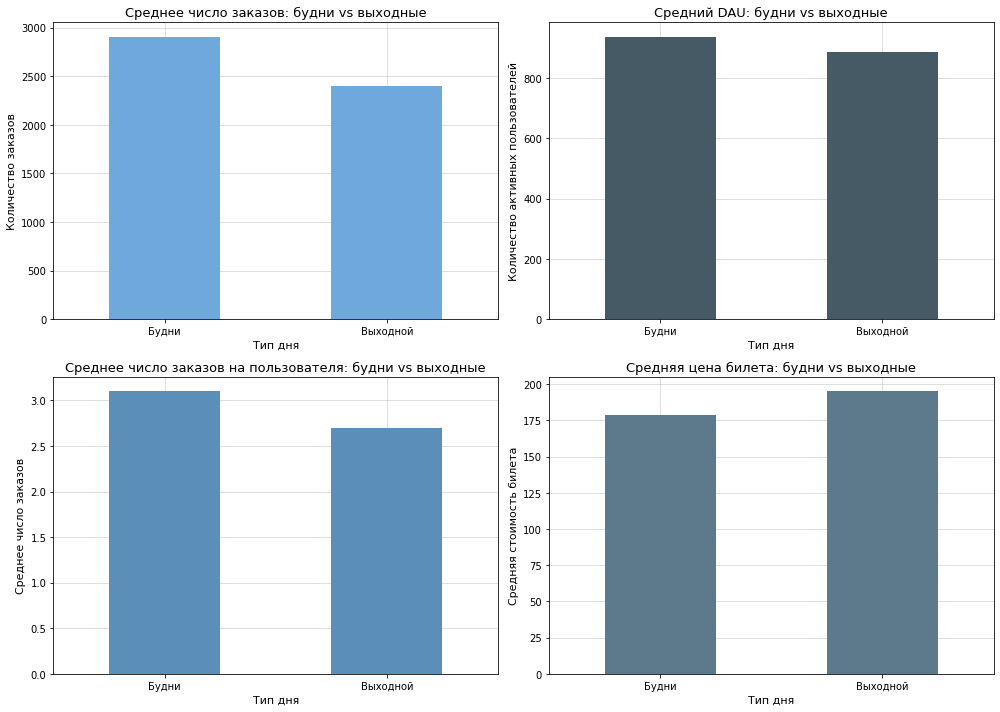

In [66]:
# Создаём фигуру и две оси
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# график количество заказов 
result['orders'].plot.bar(ax=ax1, color= '#6FA8DC')

ax1.set_title('Среднее число заказов: будни vs выходные', fontsize=13)
ax1.set_ylabel('Количество заказов', fontsize=11)
ax1.set_xlabel('Тип дня', fontsize=11)
ax1.tick_params(axis='x', rotation=0)
ax1.grid(alpha=0.5)
ax1.set_axisbelow(True)

#  график DAU 
result['dau'].plot.bar(ax=ax2, color= '#455A64')

ax2.set_title('Средний DAU: будни vs выходные', fontsize=13)
ax2.set_ylabel('Количество активных пользователей', fontsize=11)
ax2.set_xlabel('Тип дня', fontsize=11)
ax2.tick_params(axis='x', rotation=0)
ax2.grid(alpha=0.5)
ax2.set_axisbelow(True)

# График среднее число заказов
result['order_per_user'].plot.bar(ax=ax3, color= '#5B8FB9')

ax3.set_title('Среднее число заказов на пользователя: будни vs выходные', fontsize=13)
ax3.set_ylabel('Среднее число заказов', fontsize=11)
ax3.set_xlabel('Тип дня', fontsize=11)
ax3.grid(alpha=0.5)
ax3.tick_params(axis='x', rotation=0)
ax3.set_axisbelow(True)

# График средней стоимости одного билета

result['avg_ticket_rev'].plot.bar(ax=ax4,color='#5D7A8C')

ax4.set_title('Средняя цена билета: будни vs выходные', fontsize=13)
ax4.set_ylabel('Средняя стоимость билета', fontsize=11)
ax4.set_xlabel('Тип дня', fontsize=11)
ax4.tick_params(axis='x', rotation=0)
ax4.grid(alpha=0.5)
ax4.set_axisbelow(True)

plt.tight_layout()
plt.show()

Вывод: Активность пользователей демонстрирует выраженную недельную цикличность. В будни среднее число заказов на пользователя, средний DAU, среднее общее число заказов,  выше, чем в выходные. При этом средняя цена билета в наоборот, выше в выходные — 195 руб против 178 руб в будни.

В будни приходит больше пользователей и они делают больше заказов, но билеты покупают дешевле. В выходные аудитория меньше, но покупает дороже — вероятно, выбирает более премиальные мероприятия или идёт на события с высокими ценами.

### Популярные события и партнёры

Теперь посмотрим, как события распределены по регионам и партнёрам. Это позволит выделить ключевые регионы и партнёров, которые вносят наибольший вклад в выручку.

Для каждого региона посчитаем уникальное количество мероприятий и общее число заказов.

Для каждого билетного партнёра так же посчитаем общее число уникальных мероприятий, обработанных заказов и суммарную выручку с заказов билетов. Сделайте акцент на наиболее активных партнёрах.


In [67]:
# найдем топ 10 регионов по числу заказов
region_order = df_aut.region_name.value_counts()
region_order_share = df_aut.region_name.value_counts(normalize = True)
region_order_result = pd.concat([region_order.rename('Количество заказов'), 
           region_order_share.rename('Доля заказов')], 
          axis=1).head(10).rename_axis('Регион').reset_index()
region_order_result


,Регион,Количество заказов,Доля заказов
0,Каменевский регион,46684,0.276917
1,Североярская область,20718,0.122893
2,Медовская область,12044,0.071442
3,Широковская область,8715,0.051695
4,Озернинский край,7480,0.044369
5,Светополянский округ,4779,0.028348
6,Серебринская область,4467,0.026497
7,Малиновоярский округ,4412,0.026171
8,Солнечноземская область,4228,0.025079
9,Яблоневская область,4199,0.024907


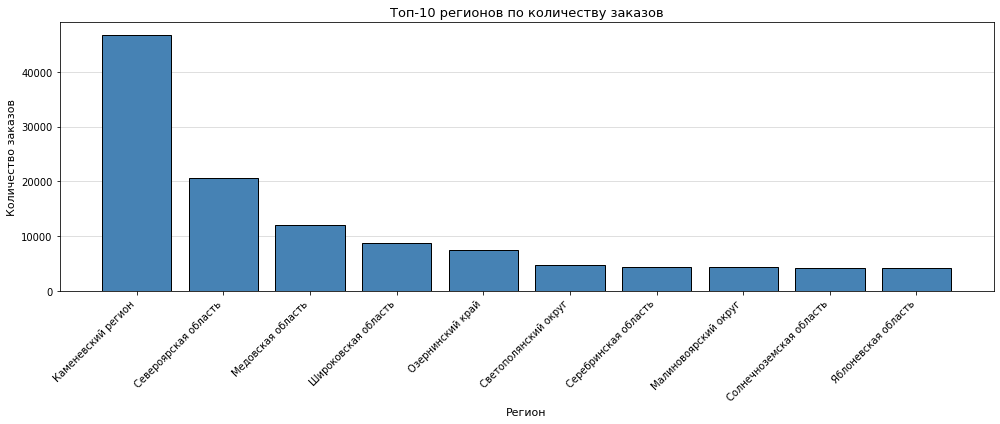

In [68]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    region_order_result['Регион'],       
    region_order_result['Количество заказов'],
    color='steelblue',
    edgecolor='black'
)

ax.set_title('Топ-10 регионов по количеству заказов', fontsize=13)
ax.set_ylabel('Количество заказов', fontsize=11)
ax.set_xlabel('Регион', fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
ax.grid(axis='y', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [69]:
# # найдем топ 10 регионов по числу событий
region_event = df_aut.groupby('region_name')['event_name'].nunique()
region_event_share = region_event / region_event.sum()
region_event_result = pd.concat([region_event.rename('Количество мероприятий'), 
           region_event_share.rename('Доля мероприятий')], 
          axis=1).sort_values(by = 'Количество мероприятий', ascending= False).head(10).rename_axis('Регион').reset_index()
region_event_result


,Регион,Количество мероприятий,Доля мероприятий
0,Каменевский регион,3280,0.234738
1,Североярская область,2254,0.161311
2,Светополянский округ,713,0.051027
3,Широковская область,674,0.048236
4,Речиновская область,494,0.035354
5,Серебринская область,401,0.028698
6,Тепляковская область,376,0.026909
7,Медовская область,360,0.025764
8,Солнечноземская область,358,0.025621
9,Яблоневская область,357,0.025549


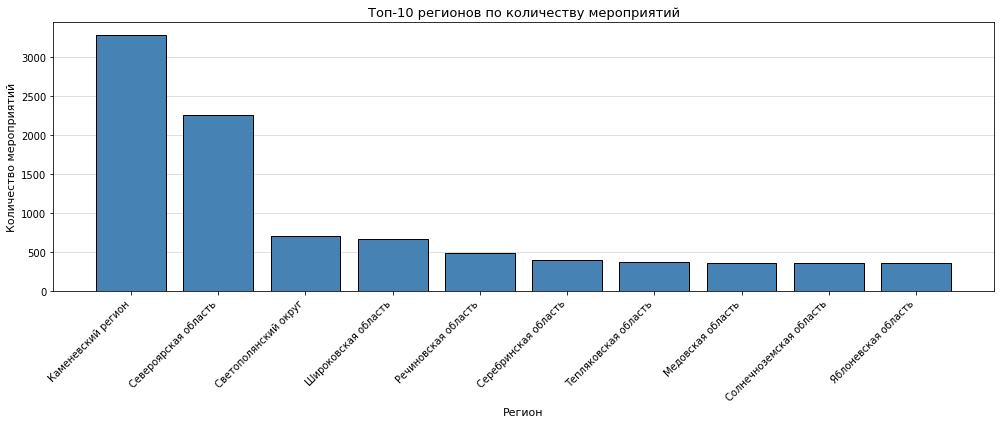

In [70]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    region_event_result['Регион'],       
    region_event_result['Количество мероприятий'],
    color='steelblue',
    edgecolor='black'
)

ax.set_title('Топ-10 регионов по количеству мероприятий', fontsize=13)
ax.set_ylabel('Количество мероприятий', fontsize=11)
ax.set_xlabel('Регион', fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
ax.grid(axis='y', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [71]:
# Топ регионов и по заказам, и по событиям
region_result = region_order_result.merge(region_event_result, on = 'Регион', how = 'inner')
region_result

,Регион,Количество заказов,Доля заказов,Количество мероприятий,Доля мероприятий
0,Каменевский регион,46684,0.276917,3280,0.234738
1,Североярская область,20718,0.122893,2254,0.161311
2,Медовская область,12044,0.071442,360,0.025764
3,Широковская область,8715,0.051695,674,0.048236
4,Светополянский округ,4779,0.028348,713,0.051027
5,Серебринская область,4467,0.026497,401,0.028698
6,Солнечноземская область,4228,0.025079,358,0.025621
7,Яблоневская область,4199,0.024907,357,0.025549


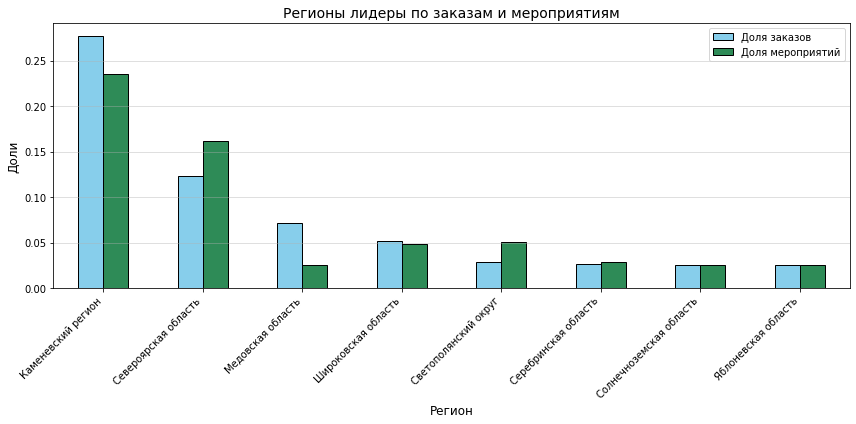

In [72]:
# Строим столбчатую диаграмму
ax = region_result[['Регион','Доля заказов', 'Доля мероприятий']].set_index('Регион')

ax.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen'],
    edgecolor='black'
)

plt.title('Регионы лидеры по заказам и мероприятиям', fontsize=14)
plt.xlabel('Регион', fontsize=12)
plt.ylabel('Доли', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

Явный лидер — Каменевский регион. Он занимает 27.7% всех заказов (46684) и 23.5% всех мероприятий (3280). Это в 2.3 раза больше ближайшего конкурента — Североярской области (12.3% заказов, 16.1% мероприятий). Вместе эти два региона формируют 40% заказов и 40% мероприятий — то есть высокую концентрацию рынка. Вероятно это большие столичные города с большим количеством проводимых мероприятий.

Интересное расхождение — Медовская область. Она на 3-м месте по заказам (7.1%, 12 044), но только на 8-м по мероприятиям (2.6%, 360).

Обратный случай — Светополянский округ. Он на 4-м месте по мероприятиям (5.1%, 713), но только на 5-м по заказам (2.8%, 4 779). Событий много, а спрос ниже — возможно, предложение опережает аудиторию, или события не пользуются популярностью.

Хвост распределения длинный. После топ-8 регионов идут регионы с долей менее 2.5% каждый. Суммарно они дают ~30% заказов и ~40% мероприятий — то есть распределение более равномерное, чем в топе, но разрыв с лидерами огромный.

Рынок высококонцентрирован. Каменевский регион — безусловный лидер и по заказам, и по мероприятиям (м.б. Москва). Североярская область — второй центр (Санкт-Петербург). Но есть дисбаланс между предложением и спросом: Медовская область покупает много, но событий мало, а Светополянский округ — наоборот. 

Теперь для каждого билетного партнёра посчитаем общее число уникальных мероприятий, обработанных заказов и суммарную выручку с заказов билетов. 

In [73]:
# Топ 10 операторов по числу заказов
service_order = df_aut.service_name.value_counts()
service_order_share = df_aut.service_name.value_counts(normalize = True)
service_order_result = pd.concat([service_order.rename('Количество заказов'), 
           service_order_share.rename('Доля заказов')], 
          axis=1).head(10).rename_axis('Билетный оператор').reset_index()
service_order_result


,Билетный оператор,Количество заказов,Доля заказов
0,Билеты без проблем,32383,0.192062
1,Лови билет!,25792,0.152971
2,Билеты в руки,25734,0.152627
3,Мой билет,19419,0.115173
4,Облачко,15478,0.091799
5,Лучшие билеты,12445,0.073811
6,Весь в билетах,9406,0.055787
7,Прачечная,5798,0.034388
8,Тебе билет!,3749,0.022235
9,Яблоко,3473,0.020598


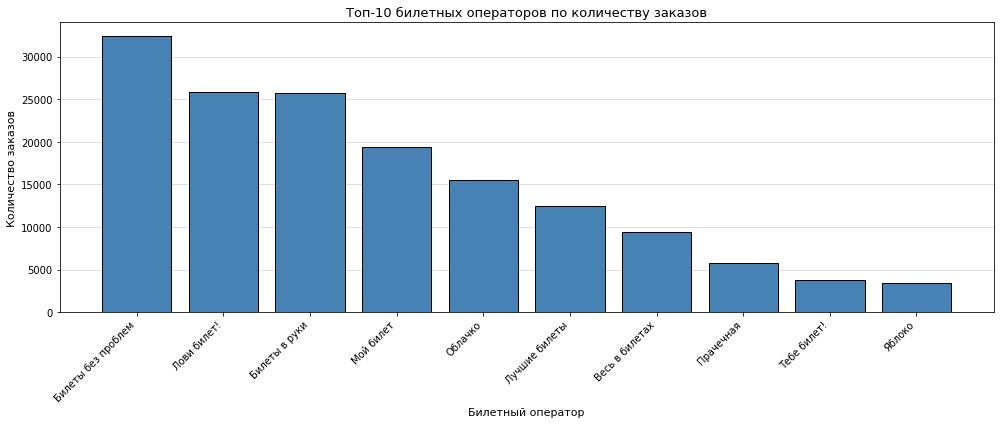

In [74]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    service_order_result['Билетный оператор'],       
    service_order_result['Количество заказов'],
    color='steelblue',
    edgecolor='black'
)

ax.set_title('Топ-10 билетных операторов по количеству заказов', fontsize=13)
ax.set_ylabel('Количество заказов', fontsize=11)
ax.set_xlabel('Билетный оператор', fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
ax.grid(axis='y', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [75]:
# Топ 10 операторов по числу событий 
service_event = df_aut.groupby('service_name')['event_name'].nunique()
service_event_share = service_event / service_event.sum()
service_event_result = pd.concat([service_event.rename('Количество мероприятий'), 
           service_event_share.rename('Доля мероприятий')], 
          axis=1).sort_values(by = 'Количество мероприятий', ascending= False).head(10).rename_axis('Билетный оператор').reset_index()
service_event_result

,Билетный оператор,Количество мероприятий,Доля мероприятий
0,Лови билет!,2870,0.199986
1,Билеты без проблем,2190,0.152603
2,Билеты в руки,2070,0.144241
3,Лучшие билеты,1210,0.084315
4,Облачко,1124,0.078322
5,Мой билет,818,0.057000
6,Тебе билет!,749,0.052191
7,Прачечная,635,0.044248
8,Весь в билетах,503,0.035050
9,Яблоко,453,0.031566


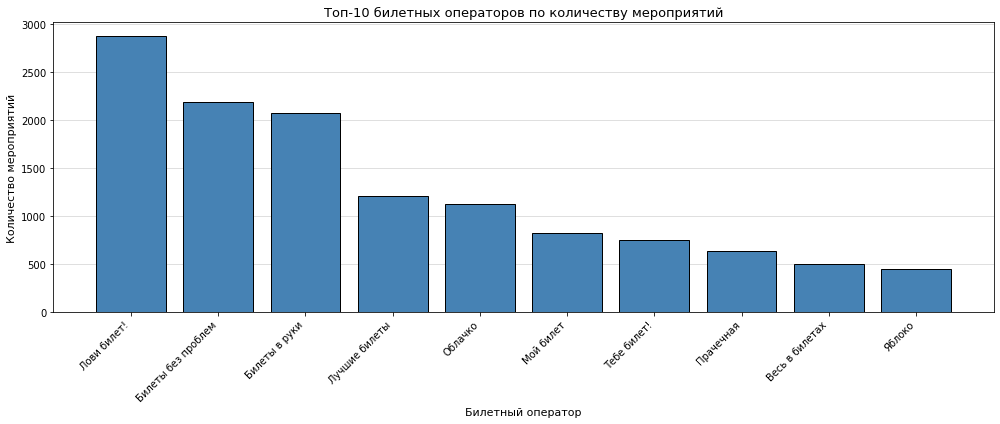

In [76]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    service_event_result['Билетный оператор'],       
    service_event_result['Количество мероприятий'],
    color='steelblue',
    edgecolor='black'
)

ax.set_title('Топ-10 билетных операторов по количеству мероприятий', fontsize=13)
ax.set_ylabel('Количество мероприятий', fontsize=11)
ax.set_xlabel('Билетный оператор', fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
ax.grid(axis='y', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [77]:
# Топ 10 операторов по суммарной выручке
service_revenue = (df_aut.groupby('service_name')['revenue_rub'].sum()/1000000)
service_revenue_share = service_revenue / service_revenue.sum()
service_revenue_result = pd.concat([service_revenue.rename('Суммарная выручка, млн руб').round(1), 
           service_revenue_share.rename('Доля выручки').round(2)], 
          axis=1).sort_values(by = 'Суммарная выручка, млн руб', ascending= False).head(10).rename_axis('Билетный оператор').reset_index()
service_revenue_result

,Билетный оператор,"Суммарная выручка, млн руб",Доля выручки
0,Билеты без проблем,12.1,0.15
1,Мой билет,10.9,0.13
2,Облачко,10.6,0.13
3,Лови билет!,10.4,0.13
4,Весь в билетах,9.3,0.11
5,Билеты в руки,7.6,0.09
6,Край билетов,3.0,0.04
7,Яблоко,2.8,0.03
8,Прачечная,2.5,0.03
9,Тебе билет!,2.1,0.03


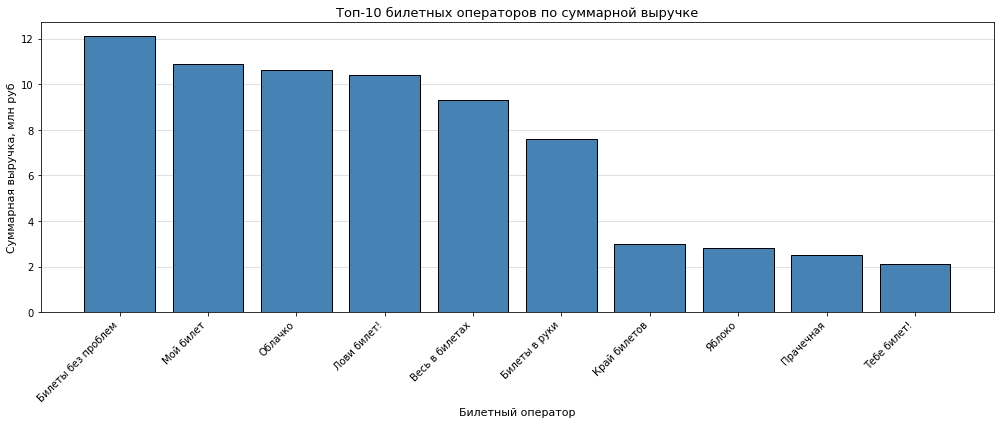

In [78]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    service_revenue_result['Билетный оператор'],       
    service_revenue_result['Суммарная выручка, млн руб'],
    color='steelblue',
    edgecolor='black'
)

ax.set_title('Топ-10 билетных операторов по суммарной выручке', fontsize=13)
ax.set_ylabel('Суммарная выручка, млн руб', fontsize=11)
ax.set_xlabel('Билетный оператор', fontsize=11)
ax.tick_params(axis='x', rotation=45)
plt.setp(ax.get_xticklabels(), ha='right')
ax.grid(axis='y', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [79]:
# Топ операторов по трем показателям
service_result = service_order_result.merge(
    service_event_result, on = 'Билетный оператор', how = 'inner').merge(
    service_revenue_result, on = 'Билетный оператор', how = 'inner')
service_result

,Билетный оператор,Количество заказов,Доля заказов,Количество мероприятий,Доля мероприятий,"Суммарная выручка, млн руб",Доля выручки
0,Билеты без проблем,32383,0.192062,2190,0.152603,12.1,0.15
1,Лови билет!,25792,0.152971,2870,0.199986,10.4,0.13
2,Билеты в руки,25734,0.152627,2070,0.144241,7.6,0.09
3,Мой билет,19419,0.115173,818,0.057000,10.9,0.13
4,Облачко,15478,0.091799,1124,0.078322,10.6,0.13
5,Весь в билетах,9406,0.055787,503,0.035050,9.3,0.11
6,Прачечная,5798,0.034388,635,0.044248,2.5,0.03
7,Тебе билет!,3749,0.022235,749,0.052191,2.1,0.03
8,Яблоко,3473,0.020598,453,0.031566,2.8,0.03


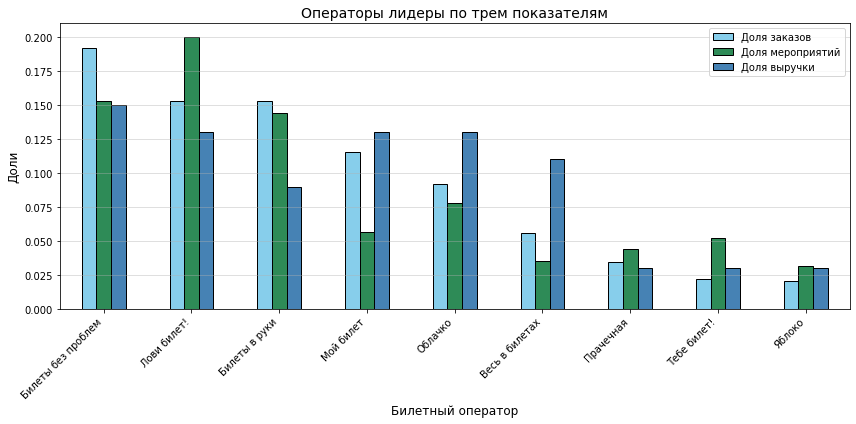

In [80]:
# Строим столбчатую диаграмму
ax =(
    service_result[['Билетный оператор','Доля заказов', 'Доля мероприятий', 'Доля выручки']]
    .set_index('Билетный оператор')
)
ax.plot(
    kind='bar',
    figsize=(12, 6),
    color=['skyblue', 'seagreen','steelblue'],
    edgecolor='black'
)

plt.title('Операторы лидеры по трем показателям', fontsize=14)
plt.xlabel('Билетный оператор', fontsize=12)
plt.ylabel('Доли', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.5)
plt.tight_layout()
plt.show()

Явного лидера нет — но есть группа-лидеров из 4–5 операторов. Топ-5 операторов формируют ~70% заказов и ~72% выручки, но разрыв между ними небольшой. Лидер по заказам — «Билеты без проблем» (19.2%, 32383 заказа), по мероприятиям — «Лови билет!» (20.0%, 2870), по выручке — тоже «Билеты без проблем» (15%, 12.1 млн руб).

Топ-3 оператора («Билеты без проблем», «Лови билет!», «Билеты в руки») дают ~50% заказов и ~40% выручки. Топ-8 — ~82% заказов и ~86% выручки. Небольшая часть операторов формирует основную массу рынка. Но в отличие от регионов, где лидер был в 2.3 раза больше второго, здесь разрыв плавный — рынок менее концентрирован.

Интересное расхождение — «Мой билет» и «Облачко». «Мой билет» на 4-м месте по заказам (11.5%, 19419), но только на 6-м по мероприятиям (5.7%, 818). То есть заказов много, а событий мало — вероятно, оператор специализируется на крупных событиях или перепродаёт билеты других операторов. При этом по выручке он на 2-м месте (13%, 10.9 млн) — значит, средний чек выше, чем у лидеров.

Обратный случай — «Лови билет!». Лидер по мероприятиям (20.0%, 2 870), 2-й по заказам (15.3%, 25 792), но только  4-й по выручке (13%, 10.4 млн). То есть событий много, но средний чек ниже — оператор работает с массовыми и доступными событиями.

Рынок билетных операторов умеренно концентрирован. Есть группа лидеров («Билеты без проблем», «Лови билет!», «Билеты в руки», «Мой билет», «Облачко»), которые дают основную выручку. Но структура у них разная: одни работают на объём (много событий, низкий чек), другие — на качество (мало событий, высокий чек). 

## Статистический анализ данных

Проверим две гипотезы, которые предполагают большую активность пользователей мобильных устройств:

Среднее количество заказов на одного пользователя мобильного приложения выше по сравнению с пользователями стационарных устройств.

Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.


### Первая гипотеза

Формулировка гипотез:

H₀ (нулевая): среднее количество заказов на одного пользователя мобильного приложения такое же, как у  пользователя стационарных устройств (μ_mobile = μ_desktop).

H₁ (альтернативная): среднее количество заказов на одного пользователя мобильного приложения выше по сравнению с пользователями стационарных устройств (μ_mobile > μ_desktop).

In [81]:
# Выделим группы мобильных и стационарных пользователей
df_mob = df_aut[df_aut.device_type_canonical == 'mobile']
df_desk = df_aut[df_aut.device_type_canonical == 'desktop']

In [82]:
# Проверим размеры этих групп
A_size= df_mob['user_id'].nunique()
B_size = df_desk['user_id'].nunique()
print(A_size, B_size)

14190 4869


In [83]:
# Проверим, есть ли пересечения между пользователями в обеих группах
A= df_mob['user_id']
B = df_desk['user_id']

intersection = list(set(A) & set(B))

if len(intersection) == 0:
    print("Пересечения между пользователями в группах не найдены. Группы независимы.")
else:
    print(f"Найдено {len(intersection)} пересекающихся пользователей")
    print(f" Это {round(len(intersection) / df_3.user_id.nunique() * 100, 2)} % от общего числа уникальных пользователей" )


Найдено 3250 пересекающихся пользователей
 Это 14.88 % от общего числа уникальных пользователей


Так как количество пересекающихся пользователей большое, то их удаление приведет к потере данных. Отнесем каждого пользователя из пересечений к преобладающему устройству

In [84]:
# Сгруппируем по пользователю и типу устройства
# Отфильтруем в порядке убывания кол-ва заказов с каждого типа устройства
user_orders = (
    df_aut.groupby(['user_id', 'device_type_canonical'])
    .size()
    .reset_index(name='orders_count')
).sort_values(by = ['user_id', 'orders_count'], ascending = [True, False])
user_orders

,user_id,device_type_canonical,orders_count
0,0005ca5e93f2cf4,mobile,1
1,000898990054619,mobile,2
2,000a55a418c128c,mobile,2
3,001e7037d013f0f,mobile,2
4,00245c702bc343e,mobile,2
...,...,...,...
19054,fff32fc9ad0f9f6,desktop,1
19056,fffcd3dde79eb2c,mobile,14
19055,fffcd3dde79eb2c,desktop,2
19057,fffeeb3c120cf0b,desktop,1


In [85]:
# Удалим пользователей с неосновным типом устройства 
#  Количество уникальных пользователей до и после очистки должно быть одинаковым
user_orders_clean = user_orders.drop_duplicates(subset='user_id', keep='first')
print(f"Пользователей до очистки: {df_aut['user_id'].nunique()}")
print(f"Пользователей после: {user_orders_clean['user_id'].nunique()}")

Пользователей до очистки: 15809
Пользователей после: 15809


In [86]:
# Снова проверим, есть ли пересечения между пользователями в обеих группах
df_mob_clean = user_orders_clean[user_orders_clean.device_type_canonical == 'mobile']
df_desk_clean = user_orders_clean[user_orders_clean.device_type_canonical == 'desktop']

A= df_mob_clean['user_id']
B = df_desk_clean['user_id']

intersection = list(set(A) & set(B))

if len(intersection) == 0:
    print("Пересечения между пользователями в группах не найдены. Группы независимы.")
else:
    print(f"Найдено {len(intersection)} пересекающихся пользователей")
    print(f" Это {round(len(intersection) / user_orders_clean.user_id.nunique() * 100, 2)} % от общего числа уникальных пользователей" )


Пересечения между пользователями в группах не найдены. Группы независимы.


In [87]:
# Выведем размеры групп после очистки
A_size= df_mob_clean['user_id'].nunique()
B_size = df_desk_clean['user_id'].nunique()
print(A_size, B_size)

13244 2565


In [88]:
# Рассчитаем процентную разницу в количестве пользователей 
P = 100*abs(A_size - B_size)/A_size
print(f"Процентная разница: {P:.2f}%")

Процентная разница: 80.63%


In [89]:
# Рассчитаем среднее число заказов на пользователя
avg = user_orders_clean.groupby('device_type_canonical')['orders_count'].mean()
avg

device_type_canonical
desktop    3.463548
mobile     9.940199
Name: orders_count, dtype: float64

In [90]:
# Проведем сравнительную статистику по группам

print("Сравнительная статистика по группам")

stats_comparison = pd.DataFrame({
    'Показатель': ['Количество пользователей', 'Среднее количество заказов', 'Медиана', 'Станд. отклонение', 'Минимум', 'Максимум'],
    'Mobile': [
        len(df_mob_clean),
        df_mob_clean['orders_count'].mean(),
        df_mob_clean['orders_count'].median(),
        df_mob_clean['orders_count'].std(),
        df_mob_clean['orders_count'].min(),
        df_mob_clean['orders_count'].max()
    ],
    'Desktop': [
        len(df_desk_clean),
        df_desk_clean['orders_count'].mean(),
        df_desk_clean['orders_count'].median(),
        df_desk_clean['orders_count'].std(),
        df_desk_clean['orders_count'].min(),
        df_desk_clean['orders_count'].max()
    ]
})



print(stats_comparison.to_string(index=False))

Сравнительная статистика по группам
                Показатель       Mobile     Desktop
  Количество пользователей 13244.000000 2565.000000
Среднее количество заказов     9.940199    3.463548
                   Медиана     2.000000    1.000000
         Станд. отклонение    70.398974   10.164671
                   Минимум     1.000000    1.000000
                  Максимум  4336.000000  250.000000


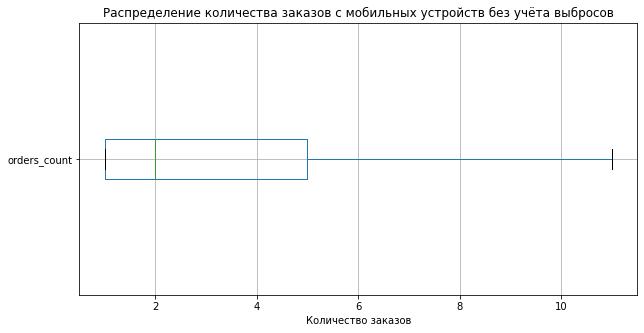

In [91]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df_mob_clean.boxplot(column='orders_count', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение количества заказов с мобильных устройств без учёта выбросов')
plt.xlabel('Количество заказов')

# Выводим график
plt.show()

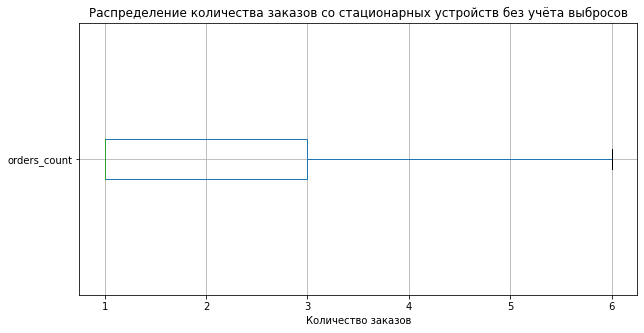

In [92]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df_desk_clean.boxplot(column='orders_count', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
# Добавляем заголовок и метки оси
plt.title('Распределение количества заказов со стационарных устройств без учёта выбросов')
plt.xlabel('Количество заказов')

# Выводим график
plt.show()

Так как данные имеют большие выбросы, для наглядности распределения на гистограмме отфильтруем данные по количеству заказов меньше 20

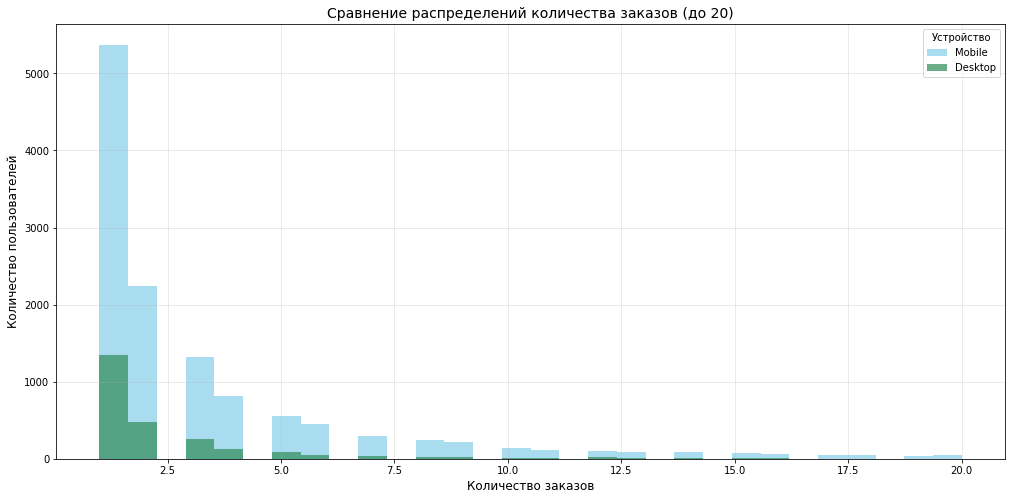

In [93]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Гистограмма для Mobile
plt.hist(
    df_mob_clean[df_mob_clean['orders_count'] <= 20]['orders_count'],
    bins=30,
    alpha=0.7,
    label='Mobile',
    color='skyblue'
)

# Гистограмма для Desktop
plt.hist(
    df_desk_clean[df_desk_clean['orders_count'] <= 20]['orders_count'],
    bins=30,
    alpha=0.7,
    label='Desktop',
    color='seagreen'
)

plt.xlabel('Количество заказов', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)
plt.title('Сравнение распределений количества заказов (до 20)', fontsize=14)
plt.legend(title='Устройство')
plt.grid(True, alpha=0.3)
plt.show()

Проведя анализ данных, видно, что распределение числа заказов не нормальное. Оно скошено вправо — большинство пользователей делают 1–2 заказа, но есть единицы, кто делает тысячи. Именно они «раздувают» среднее и стандартное отклонение.

Среднее (9.94) в 5 раз больше медианы (2.0) — сильная скошенность.

Стандартное отклонение (70.4) в 7 раз больше среднего.

Максимум 4 336 заказов — экстремальные выбросы.

T-тест предполагает нормальное распределение (или хотя бы приближенное к нему).
Поскольку распределение числа заказов на пользователя оказалось сильно скошенным, для проверки гипотезы были использованы два теста: t-тест Уэлча (для сравнения средних) и тест Манна-Уитни (непараметрический, устойчивый к скошенности).

In [94]:
# Выберем уровень статистической значимости 0.05
alpha = 0.05

# Проведем t-тест Уэлча
result = st.ttest_ind(
    df_mob_clean['orders_count'],
    df_desk_clean['orders_count'],
    equal_var=False,
    alternative='greater'
)

print('p-значение:', result.pvalue)

if result.pvalue < alpha:
    print("Нулевая гипотеза отвергается: среднее число заказов у мобильных пользователей")
    print("статистически значимо выше, чем у стационарных.")
else:
    print("Нулевая гипотеза не отвергается: нет статистических оснований утверждать,")
    print("что среднее число заказов у мобильных пользователей выше, чем у стационарных.")

p-значение: 4.921517859229302e-24
Нулевая гипотеза отвергается: среднее число заказов у мобильных пользователей
статистически значимо выше, чем у стационарных.


In [95]:
# Проведем тест Манна-Уитни

alpha = 0.05

mw_test = st.mannwhitneyu(
    df_mob_clean['orders_count'],
    df_desk_clean['orders_count'],
    alternative='greater'
)

if mw_test.pvalue > alpha:
    print(f'pvalue={mw_test.pvalue} > {alpha}')
    print("Нулевая гипотеза не отвергается: нет статистических оснований утверждать,")
    print("что число заказов у мобильных пользователей выше, чем у стационарных.")
else:
    print(f'pvalue={mw_test.pvalue} < {alpha}')
    print("Нулевая гипотеза отвергается: число заказов у мобильных пользователей")
    print("статистически значимо выше, чем у стационарных.")



pvalue=4.036012611530109e-50 < 0.05
Нулевая гипотеза отвергается: число заказов у мобильных пользователей
статистически значимо выше, чем у стационарных.


Оба теста показали, что  p-value , что меньше уровня значимости 0.05 — нулевая гипотеза отвергается. Медианное число заказов у мобильных пользователей составило 2, у стационарных — 1. Разница составляет 100%, что подтверждает гипотезу не только статистически, но и практически. Cреднее число заказов у мобильных пользователей так же
статистически значимо выше, чем у стационарных

### Вторая гипотеза


Формулировка гипотез:

H₀ (нулевая): среднее время между заказами пользователей мобильных приложений такое же как у пользователей стационарных устройств (μ_mobile = μ_desktop).

H₁ (альтернативная): Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств (μ_mobile > μ_desktop).

Для начала проведем анализ по уже созданному столбцу `days_since_prev` с количеством дней с предыдущей покупки для каждого пользователя

In [96]:
# Соединим исходный датафрейм с датафреймом с преобладающим устройством
df_4= df_aut.merge(user_orders_clean, on = 'user_id', how = 'inner')

print(f"Пользователей до очистки: {df_aut['user_id'].nunique()}")
print(f"Пользователей после: {df_4['user_id'].nunique()}")

Пользователей до очистки: 15809
Пользователей после: 15809


In [97]:
# удалим изначальную колонку с типом устройств и переименуем колонку с преобладающим устройством, 
# как основное
df_4 = df_4.drop(columns=['device_type_canonical_x'])
df_4 = df_4.rename(columns={'device_type_canonical_y': 'device_type_canonical'})

In [98]:
# Удалим строки, где days_since_prev NAN, те где был только один заказ
df_filter = df_4.dropna(subset=['days_since_prev'])
print(f"Было строк: {len(df_4)}")
print(f"Стало строк: {len(df_filter)}")
print(f"Удалено пользователей с одним заказом: {len(df_4) - len(df_filter)}")

Было строк: 168607
Стало строк: 160265
Удалено пользователей с одним заказом: 8342


In [99]:
# Выделим группы мобильных и стационарных пользователей
df_mob = df_filter[df_filter.device_type_canonical == 'mobile']
df_desk = df_filter[df_filter.device_type_canonical == 'desktop']

In [100]:
# Проверим, есть ли пересечения между пользователями в обеих группах
A= df_mob['user_id']
B = df_desk['user_id']

intersection = list(set(A) & set(B))

if len(intersection) == 0:
    print("Пересечения между пользователями в группах не найдены. Группы независимы.")
else:
    print(f"Найдено {len(intersection)} пересекающихся пользователей")
    print(f" Это {round(len(intersection) / df_filter.user_id.nunique() * 100, 2)} % от общего числа уникальных пользователей" )


Пересечения между пользователями в группах не найдены. Группы независимы.


In [101]:
# Найдем размеры групп 
A_size= df_mob['user_id'].nunique()
B_size = df_desk['user_id'].nunique()
print(A_size, B_size)

9360 1839


In [102]:
# Рассчитаем процентную разницу в количестве пользователей 
P = 100*abs(A_size - B_size)/A_size
print(f"Процентная разница: {P:.2f}%")

Процентная разница: 80.35%


In [103]:
# Посчитаем среднее количество дней для каждого пользователя
order_intervals = (
    df_filter.groupby(['user_id', 'device_type_canonical'])['days_since_prev']
    .mean()
    .reset_index(name='avg_interval')
)
order_intervals

,user_id,device_type_canonical,avg_interval
0,0005ca5e93f2cf4,mobile,75.000000
1,000898990054619,mobile,51.000000
2,000a55a418c128c,mobile,16.000000
3,001e7037d013f0f,mobile,43.500000
4,00245c702bc343e,mobile,27.500000
...,...,...,...
11194,ffe73c50cbd71fc,mobile,0.000000
11195,ffed3ff067d4f12,mobile,26.000000
11196,fff13b79bd47d7c,mobile,20.666667
11197,fff32fc9ad0f9f6,desktop,74.000000


In [104]:
# Среднее количество дней между заказами
avg = order_intervals.groupby('device_type_canonical')['avg_interval'].mean()
avg

device_type_canonical
desktop    23.952928
mobile     20.699856
Name: avg_interval, dtype: float64

In [105]:
# Проведем сравнительную статистику по группам

print("Сравнительная статистика по группам")

stats_comparison = pd.DataFrame({
    'Показатель': ['Количество пользователей', 'Среднее количество дней между заказами', 'Медиана', 'Станд. отклонение', 'Минимум', 'Максимум'],
    'Mobile': [
        len(df_mob),
        df_mob['days_since_prev'].mean(),
        df_mob['days_since_prev'].median(),
        df_mob['days_since_prev'].std(),
        df_mob['days_since_prev'].min(),
        df_mob['days_since_prev'].max()
    ],
    'Desktop': [
        len(df_desk),
        df_desk['days_since_prev'].mean(),
        df_desk['days_since_prev'].median(),
        df_desk['days_since_prev'].std(),
        df_desk['days_since_prev'].min(),
        df_desk['days_since_prev'].max()
    ]
})



print(stats_comparison.to_string(index=False))

Сравнительная статистика по группам
                            Показатель        Mobile      Desktop
                    Количество заказов 150163.000000 10102.000000
Среднее количество дней между заказами      3.264486     8.971095
                               Медиана      0.000000     0.000000
                     Станд. отклонение     12.341022    21.024322
                               Минимум      0.000000     0.000000
                              Максимум    148.000000   147.000000


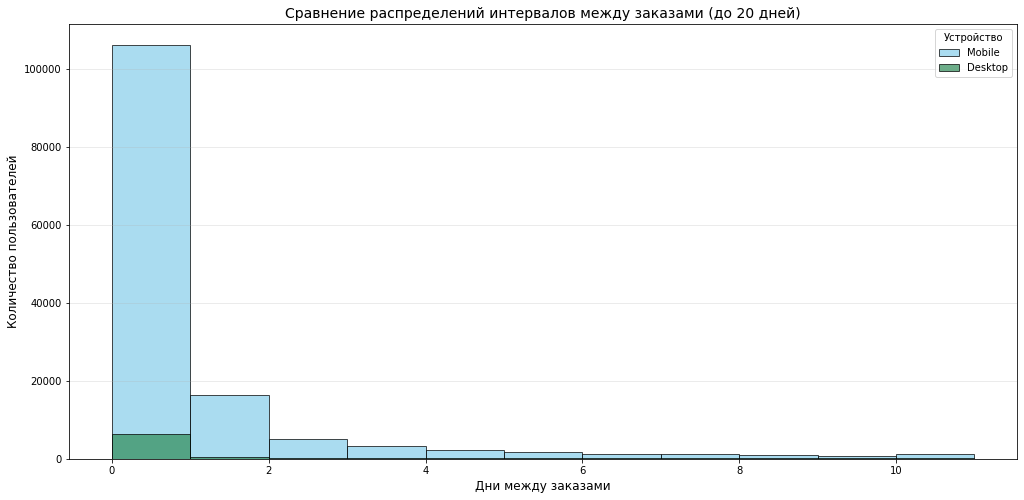

In [106]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Ограничиваем данные: оставляем только интервалы ≤ 20 дней
mob_filtered = df_mob[df_mob['days_since_prev'] <= 20]['days_since_prev']
desk_filtered = df_desk[df_desk['days_since_prev'] <= 20]['days_since_prev']

# Гистограмма для Mobile
plt.hist(
    mob_filtered,
    bins=range(0, 12),
    alpha=0.7,
    label='Mobile',
    color='skyblue',
    edgecolor='black'
)

# Гистограмма для Desktop
plt.hist(
    desk_filtered,
    bins=range(0, 12),
    alpha=0.7,
    label='Desktop',
    color='seagreen',
    edgecolor='black'
)

plt.xlabel('Дни между заказами', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)
plt.title('Сравнение распределений интервалов между заказами (до 20 дней)', fontsize=14)
plt.legend(title='Устройство')
plt.grid(axis='y', alpha=0.3)
plt.show()

Для сравнения средних двух групп будем использовать t-тест Уэлча. 

Дополнительно проведём тест Манна-Уитни — непараметрический аналог t-теста. Он не требует нормальности распределения и устойчив к выбросам. Распределение времени между заказами скошено — есть длинные интервалы, которые искажают средние.

In [107]:
# Выберем уровень статистической значимости 0.05
alpha = 0.05

# Проведем t-тест Уэлча
result = st.ttest_ind(
    df_mob['days_since_prev'],
    df_desk['days_since_prev'],
    equal_var=False,
    alternative='greater'
)

print('p-значение:', result.pvalue)

if result.pvalue < alpha:
    print("Нулевая гипотеза отвергается: среднее число заказов у мобильных пользователей")
    print("статистически значимо выше, чем у стационарных.")
else:
    print("Нулевая гипотеза не отвергается: нет статистических оснований утверждать,")
    print("что среднее число заказов у мобильных пользователей выше, чем у стационарных.")

p-значение: 1.0
Нулевая гипотеза не отвергается: нет статистических оснований утверждать,
что среднее число заказов у мобильных пользователей выше, чем у стационарных.


In [108]:


alpha = 0.05

mw_test = st.mannwhitneyu(
    df_mob['days_since_prev'],
    df_desk['days_since_prev'],
    alternative='greater'
)

if mw_test.pvalue > alpha:
    print(f'pvalue={mw_test.pvalue} > {alpha}')
    print("Нулевая гипотеза не отвергается: нет статистических оснований утверждать,")
    print("что число заказов у мобильных пользователей выше, чем у стационарных.")
else:
    print(f'pvalue={mw_test.pvalue} < {alpha}')
    print("Нулевая гипотеза отвергается: число заказов у мобильных пользователей")
    print("статистически значимо выше, чем у стационарных.")



pvalue=1.0 > 0.05
Нулевая гипотеза не отвергается: нет статистических оснований утверждать,
что число заказов у мобильных пользователей выше, чем у стационарных.


Для проверки гипотезы использованы t-тест Уэлча и тест Манна-Уитни . Однако колонка `days_since_prev` оказалась непригодной для анализа: она измеряет разницу в днях, из-за чего интервалы в течение одного дня «схлопываются» в 0. Медиана в обеих группах равна 0, распределение сильно скошено, а оба теста дают p = 1.0 — тесты не видят разницы. Это не означает, что разницы нет — это означает, что данные не позволяют её обнаружить. Для корректного анализа интервалы пересчитаем в часах на основе `created_ts_msk`.

In [109]:
# Отфильтруем очищенный по основному устройству датафрейм по пользователю и дате заказа
df_4 = df_4.sort_values(by=['user_id', 'created_ts_msk'])

In [110]:
#  Получим предыдущую дату для каждого заказа
df_4['prev_ts'] = df_4.groupby('user_id')['created_ts_msk'].shift(1)

#  Посчитаем интервал в часах
df_4['hours_since_prev'] = (
    df_4['created_ts_msk'] - df_4['prev_ts']
).dt.total_seconds() / 3600

#  Уберем строки с пропусками (первый заказ каждого пользователя)
df_intervals = df_4.dropna(subset=['hours_since_prev'])

#  Проверим результат
print(df_intervals[['user_id', 'created_ts_msk', 'hours_since_prev']].head(10))
print(f"Пользователей было: {df_4['user_id'].nunique()}") 
print(f"Пользователей осталось: {df_intervals['user_id'].nunique()}")
print(f"Пользователей удалено: {df_4['user_id'].nunique() - df_intervals['user_id'].nunique()}")

            user_id      created_ts_msk  hours_since_prev
2   000898990054619 2024-10-23 15:12:00        448.645833
4   000a55a418c128c 2024-10-15 10:29:04        374.831111
6   001e7037d013f0f 2024-09-29 22:58:14        313.749167
8   00245c702bc343e 2024-10-25 12:34:20        710.168889
10  0028d17a676f8c8 2024-10-06 00:35:19        675.554444
11  002b75ca606ba46 2024-10-02 16:05:45          2.186667
13  002b75ca606ba46 2024-10-16 18:52:55        338.786111
14  002b75ca606ba46 2024-10-16 18:57:09          0.070556
19  002ec276eee9b0b 2024-09-21 14:05:16        335.478333
20  002ec276eee9b0b 2024-09-21 14:07:15          0.033056
Пользователей было: 15809
Пользователей осталось: 9396
Пользователей удалено: 6413


In [111]:
# Разделим на группы
df_mob_hours = df_intervals[df_intervals.device_type_canonical == 'mobile']
df_desk_hours = df_intervals[df_intervals.device_type_canonical == 'desktop']

In [112]:
# Проверим, есть ли пересечения между пользователями в обеих группах
A= df_mob_hours['user_id']
B = df_desk_hours['user_id']

intersection = list(set(A) & set(B))

if len(intersection) == 0:
    print("Пересечения между пользователями в группах не найдены. Группы независимы.")
else:
    print(f"Найдено {len(intersection)} пересекающихся пользователей")
    print(f" Это {round(len(intersection) / df_filter.user_id.nunique() * 100, 2)} % от общего числа уникальных пользователей" )


Пересечения между пользователями в группах не найдены. Группы независимы.


In [113]:
# Посчитаем размер групп
A_size= df_mob_hours['user_id'].nunique()
B_size = df_desk_hours['user_id'].nunique()
print(A_size, B_size)

7871 1525


In [114]:
# Рассчитаем процентную разницу в количестве пользователей 
P = 100*abs(A_size - B_size)/A_size
print(f"Процентная разница: {P:.2f}%")

Процентная разница: 80.63%


In [115]:
# Сгруппируем данные для расчета среднего интервала
order_intervals_hours = (
    df_intervals.groupby(['user_id', 'device_type_canonical'])['hours_since_prev']
    .mean()
    .reset_index(name='avg_interval')
)
order_intervals_hours

,user_id,device_type_canonical,avg_interval
0,000898990054619,mobile,448.645833
1,000a55a418c128c,mobile,374.831111
2,001e7037d013f0f,mobile,313.749167
3,00245c702bc343e,mobile,710.168889
4,0028d17a676f8c8,desktop,675.554444
...,...,...,...
9391,ffe364dd8211157,mobile,0.467500
9392,ffe73c50cbd71fc,mobile,2.183056
9393,ffed3ff067d4f12,mobile,552.381389
9394,fff13b79bd47d7c,mobile,401.267500


In [116]:
# Среднее время между заказами
avg = order_intervals_hours.groupby('device_type_canonical')['avg_interval'].mean()
avg

device_type_canonical
desktop    189.103247
mobile     143.906468
Name: avg_interval, dtype: float64

In [117]:
# Проведем сравнительную статистику по группам

print("Сравнительная статистика по группам")

stats_comparison = pd.DataFrame({
    'Показатель': ['Количество пользователей', 'Среднее время между заказами (в часах)', 'Медиана', 'Станд. отклонение', 'Минимум', 'Максимум'],
    'Mobile': [
        len(df_mob_hours),
        df_mob_hours['hours_since_prev'].mean(),
        df_mob_hours['hours_since_prev'].median(),
        df_mob_hours['hours_since_prev'].std(),
        df_mob_hours['hours_since_prev'].min(),
        df_mob_hours['hours_since_prev'].max()
    ],
    'Desktop': [
        len(df_desk_hours),
        df_desk_hours['hours_since_prev'].mean(),
        df_desk_hours['hours_since_prev'].median(),
        df_desk_hours['hours_since_prev'].std(),
        df_desk_hours['hours_since_prev'].min(),
        df_desk_hours['hours_since_prev'].max()
    ]
})



print(stats_comparison.to_string(index=False))

Сравнительная статистика по группам
                            Показатель        Mobile     Desktop
              Количество пользователей 143823.000000 8975.000000
Среднее время между заказами (в часах)     32.806449   77.280803
                               Медиана      0.545833    0.071111
                     Станд. отклонение    107.583460  189.087424
                               Минимум      0.000000    0.000000
                              Максимум   1417.633889 1408.546944


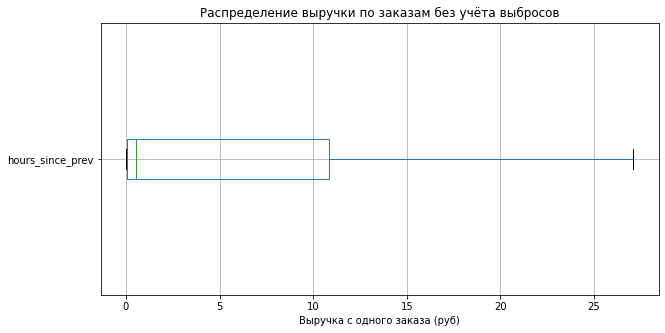

In [118]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df_mob_hours.boxplot(column='hours_since_prev', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение выручки по заказам без учёта выбросов')
plt.xlabel('Выручка с одного заказа (руб)')

# Выводим график
plt.show()

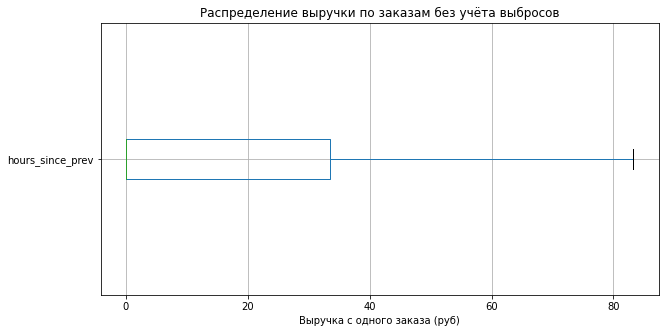

In [119]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 5))

# Строим диаграмму размаха значений в столбце funding_total_usd
df_desk_hours.boxplot(column='hours_since_prev', vert=False, showfliers=False)

# Добавляем заголовок и метки оси
plt.title('Распределение выручки по заказам без учёта выбросов')
plt.xlabel('Выручка с одного заказа (руб)')

# Выводим график
plt.show()

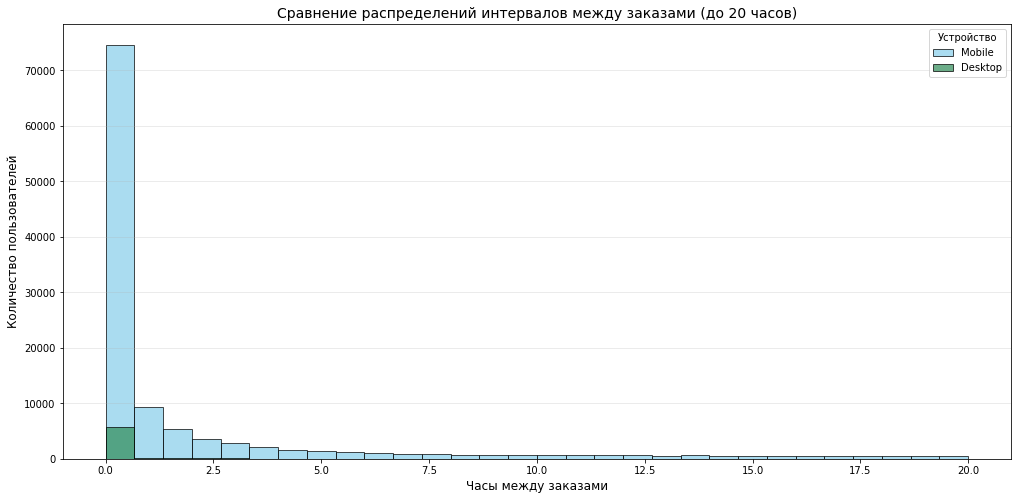

In [121]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(17, 8))

# Ограничиваем данные: оставляем только интервалы ≤ 20 часов
mob_filtered_hours = df_mob_hours[df_mob_hours['hours_since_prev'] <= 20]['hours_since_prev']
desk_filtered_hours = df_desk_hours[df_desk_hours['hours_since_prev'] <= 20]['hours_since_prev']

# Гистограмма для Mobile
plt.hist(
    mob_filtered_hours,
    bins=30,
    alpha=0.7,
    label='Mobile',
    color='skyblue',
    edgecolor='black'
)

# Гистограмма для Desktop
plt.hist(
    desk_filtered_hours,
    bins=30,
    alpha=0.7,
    label='Desktop',
    color='seagreen',
    edgecolor='black'
)

plt.xlabel('Часы между заказами', fontsize=12)
plt.ylabel('Количество пользователей', fontsize=12)
plt.title('Сравнение распределений интервалов между заказами (до 20 часов)', fontsize=14)
plt.legend(title='Устройство')
plt.grid(axis='y', alpha=0.3)
plt.show()

Проведем так же оба теста

In [122]:
# Выберем уровень статистической значимости 0.05
alpha = 0.05

# Проведем t-тест Уэлча
result = st.ttest_ind(
    df_mob_hours['hours_since_prev'],
    df_desk_hours['hours_since_prev'],
    equal_var=False,
    alternative='greater'
)

print('p-значение:', result.pvalue)

if result.pvalue < alpha:
    print("Нулевая гипотеза отвергается: среднее время между заказами у мобильных пользователей")
    print("статистически значимо выше, чем у стационарных.")
else:
    print("Нулевая гипотеза не отвергается: нет статистических оснований утверждать,")
    print("что среднее время между заказами у мобильных пользователей выше, чем у стационарных.")

p-значение: 1.0
Нулевая гипотеза не отвергается: нет статистических оснований утверждать,
что среднее время между заказами у мобильных пользователей выше, чем у стационарных.


In [123]:
alpha = 0.05

mw_test = st.mannwhitneyu(
    df_mob_hours['hours_since_prev'],
    df_desk_hours['hours_since_prev'],
    alternative='greater'
)

if mw_test.pvalue > alpha:
    print(f'pvalue = {mw_test.pvalue:.4f} > {alpha}')
    print("Нулевая гипотеза не отвергается:")
    print("нет статистических оснований утверждать, что время между заказами")
    print("у мобильных пользователей в среднем больше, чем у стационарных.")
else:
    print(f'pvalue = {mw_test.pvalue:.4e} < {alpha}')
    print("Нулевая гипотеза отвергается:")
    print("время между заказами у мобильных пользователей статистически значимо")
    print("больше, чем у стационарных.")


pvalue = 2.1913e-109 < 0.05
Нулевая гипотеза отвергается:
время между заказами у мобильных пользователей статистически значимо
больше, чем у стационарных.


Для проверки гипотезы использованы два теста: t-тест Уэлча (сравнение средних) и тест Манна-Уитни (сравнение распределений). Результаты различаются: t-тест не выявил значимых различий (p = 1.0), а Манна-Уитни показал высокую значимость (p < 0.001). Причина — в сильной скошенности распределения времени между заказами (медианы 0.55 и 0.07 часа при средних 32.8 и 77.3 часа). T-тест чувствителен к выбросам, которые искажают средние, а Манн-Уитни устойчив к ним. Поскольку данные не нормальны распределены, результат второго теста более надёжен.

Вывод: время между заказами у мобильных пользователей статистически значимо выше, чем у стационарных. Это означает, что мобильные пользователи делают заказы реже, а не чаще.

## Общий вывод и рекомендации

### О данных

В проекте использовались три датасета сервиса Яндекс Афиша за 2024 год: заказы билетов (`final_tickets_orders_df`), информация о мероприятиях и площадках (`final_tickets_events_df`) и курс тенге к рублю (`final_tickets_tenge_df`). После объединения и предобработки рабочий датасет составил 287932 строки и 31 столбец. Данные охватывают заказы с июня по октябрь 2024 года и содержат информацию как по мобильным, так и по стационарным устройствам, в двух валютах (рубли и тенге), которые были приведены к единой — рублю.

### Основные результаты анализа

**Сезонность и рост спроса.** С июня по октябрь число заказов выросло почти в 3 раза (с ~34 тыс. до ~99 тыс. в месяц). DAU также стабильно рос: с ~560 до ~1270 пользователей в день. Это говорит о росте популярности сервиса в осенний период.

**Структура спроса.** Самая востребованная категория — **концерты** (~37–43% заказов), далее «другое» (~20–27%) и **театр** (~20–25%). Осенью доля концертов и «другого» снизилась, а доля **театра** и **спорта** выросла — что логично: осенью начинается театральный сезон и спортивные чемпионаты.

**Средний чек.** Единого тренда нет. В большинстве категорий средняя стоимость билета осенью снизилась (сильнее всего — театр −17.8%, ёлки −15.4%, концерты −12.0%), при этом стендап (+5.8%) и выставки (+4.8%) подорожали. Самые дорогие билеты — на концерты и ёлки, самые дешёвые — на спорт и «другое».

**Возрастной профиль.** Осенью выросла доля «семейных» категорий (0+, 12+), доля 16+ и особенно 18+ снизилась — структура аудитории сместилась в сторону более молодой и семейной.

**Недельная цикличность.** В будни больше заказов, выше DAU и больше заказов на пользователя, но средняя цена билета ниже (178 руб против 195 руб в выходные). В выходные аудитория меньше, но покупает дороже.

**Регионы.** Явный лидер — **Каменевский регион** (27.7% заказов, 23.5% мероприятий), второй — **Североярская область** (12.3% и 16.1%). Вместе они формируют ~40% рынка. Интересный дисбаланс: Медовская область много покупает, но мало событий; Светополянский округ — наоборот.

**Партнёры.** Группа лидеров — 4–5 операторов, дающих ~70% заказов и ~72% выручки. Разрыв между ними небольшой, рынок умеренно концентрирован. Лидер по заказам и выручке — **«Билеты без проблем»** (19.2% заказов, 12.1 млн руб), по мероприятиям — **«Лови билет!»** (20.0%). «Мой билет» — пример оператора с малым числом событий, но высоким средним чеком.

### Проверка гипотез

1. **Среднее число заказов на мобильного пользователя выше, чем у десктопного** — подтверждена. Оба теста (t-тест Уэлча и Манн-Уитни) дали p < 0.001. Медиана: 2 заказа у мобильных против 1 у десктопных.

2. **Среднее время между заказами у мобильных пользователей выше** — подтверждена по тесту Манн-Уитни (p < 0.001), но t-тест различий не выявил (p = 1.0) из-за сильной скошенности распределения. Результат устойчивого непараметрического теста надёжнее: мобильные пользователи делают заказы реже.

### Рекомендации

1. **Сфокусироваться на мобильном канале** — он даёт ~80% заказов и показывает более высокую вовлечённость (больше заказов на пользователя). Стоит развивать push-уведомления и персонализировать предложения.

2. **Учитывать сезонность в маркетинге.** Осень — пик активности. Стоит усиливать рекламные кампании к сентябрю, а также развивать «семейные» категории (0+, 12+), доля которых растёт.

3. **Работа с буднями.** В будни приходит больше пользователей, но чек ниже. Можно стимулировать покупки в будни скидками/промо, а в выходные — продвигать премиальные события.

4. **Развивать недозагруженные регионы.** В Светополянском округе много событий, но мало заказов — стоит усилить там  работу с аудиторией. Медовская область, наоборот, требует большего предложения событий.

5. **Укреплять отношения с топ-операторами** («Билеты без проблем», «Лови билет!», «Билеты в руки», «Мой билет», «Облачко») — они формируют ~70% выручки. При этом учитывать их разные стратегии: одни работают на объём, другие — на средний чек.

6. **Анализ выбросов** Повторно провести тесты, исключив аномальных пользователей (например, с числом заказов > 100). Это позволит убедиться, что результаты не обусловлены несколькими корпоративными клиентами.

7. Так же можно проверьте гипотезу: средняя стоимость одного билета (или заказа) выше у пользователей десктопных устройств, чем мобильных. 